In [ ]:
!pip install -q pymupdf pandas numpy tiktoken

In [ ]:
import fitz
import re
import pandas as pd
import numpy as np
import tiktoken
from google.colab import files

uploaded = files.upload()

pdf_path = next(iter(uploaded.keys()))

doc = fitz.open(pdf_path)

print("Total pages:", len(doc))

raw_text = ""

for page_num, page in enumerate(doc):
    raw_text += page.get_text("text") + "\n"

print("Extracted characters:", len(raw_text))
print("Extracted words:", len(raw_text.split()))
print(raw_text[:2000])

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Saving 1934-7685-002.2025.issue-225-en.pdf to 1934-7685-002.2025.issue-225-en (2).pdf
Total pages: 162
Extracted characters: 442947
Extracted words: 65827

 
© 2025 International Monetary Fund 
IMF Country Report No. 25/225 
ZAMBIA 
2025 ARTICLE IV CONSULTATION, FIFTH REVIEW 
UNDER THE EXTENDED CREDIT FACILITY 
ARRANGEMENT, AND FINANCING ASSURANCES 
REVIEW—PRESS RELEASE; STAFF REPORT; AND 
STATEMENT BY THE EXECUTIVE DIRECTOR FOR 
ZAMBIA 
In the context of the 2025 Article IV Consultation, Fifth Review Under the Extended Credit 
Facility Arrangement, and Financing Assurances Review, the following documents have 
been released and are included in this package: 
 
• 
A Press Release including a statement by the Chair of the Executive Board and 
summarizing the views of the Executive Board as expressed during its July 25, 2025 
consideration of the staff report on issues related to the 2025 Article IV Consultation, 
Fifth Review Under the Extended Credit Facility Arrangement, and Financing

In [ ]:
import re

cleaned_text = raw_text

cleaned_text = cleaned_text.replace("\x00", " ")
cleaned_text = re.sub(r'\r', '\n', cleaned_text)
cleaned_text = re.sub(r'[ \t]+', ' ', cleaned_text)
cleaned_text = re.sub(r'\n{3,}', '\n\n', cleaned_text)

cleaned_text = re.sub(
    r'(?<!\n)-\n(?=[a-z])',
    '',
    cleaned_text
)

cleaned_text = cleaned_text.strip()

print("Original characters:", len(raw_text))
print("Cleaned characters:", len(cleaned_text))
print("Original words:", len(raw_text.split()))
print("Cleaned words:", len(cleaned_text.split()))

print("\nCleaned text preview:\n")
print(cleaned_text[:2000])

Original characters: 442947
Cleaned characters: 438305
Original words: 65827
Cleaned words: 65784

Cleaned text preview:

© 2025 International Monetary Fund 
IMF Country Report No. 25/225 
ZAMBIA 
2025 ARTICLE IV CONSULTATION, FIFTH REVIEW 
UNDER THE EXTENDED CREDIT FACILITY 
ARRANGEMENT, AND FINANCING ASSURANCES 
REVIEW—PRESS RELEASE; STAFF REPORT; AND 
STATEMENT BY THE EXECUTIVE DIRECTOR FOR 
ZAMBIA 
In the context of the 2025 Article IV Consultation, Fifth Review Under the Extended Credit 
Facility Arrangement, and Financing Assurances Review, the following documents have 
been released and are included in this package: 
 
• 
A Press Release including a statement by the Chair of the Executive Board and 
summarizing the views of the Executive Board as expressed during its July 25, 2025 
consideration of the staff report on issues related to the 2025 Article IV Consultation, 
Fifth Review Under the Extended Credit Facility Arrangement, and Financing 
Assurances Review. 
• 
The Staff R

In [ ]:
encoding = tiktoken.get_encoding("cl100k_base")

tokens = encoding.encode(cleaned_text)

chunk_size = 400
overlap = 50
step = chunk_size - overlap

chunks = []

for i, start in enumerate(range(0, len(tokens), step)):
    end = min(start + chunk_size, len(tokens))

    chunk_tokens = tokens[start:end]
    chunk_text = encoding.decode(chunk_tokens)

    chunks.append({
        "chunk_id": i + 1,
        "start_token": start,
        "end_token": end,
        "token_count": len(chunk_tokens),
        "text": chunk_text
    })

    if end == len(tokens):
        break

chunks_df = pd.DataFrame(chunks)

print("Total tokens:", len(tokens))
print("Chunk size:", chunk_size)
print("Overlap:", overlap)
print("Total chunks:", len(chunks))
print("Average chunk tokens:", round(chunks_df["token_count"].mean(), 2))

display(chunks_df.head(5))

Total tokens: 119206
Chunk size: 400
Overlap: 50
Total chunks: 341
Average chunk tokens: 399.43


,chunk_id,start_token,end_token,token_count,text
0,1,0,400,400,© 2025 International Monetary Fund \nIMF Count...
1,2,350,750,400,transparency policy allows for the deletion o...
2,3,700,1100,400,38month Extended Credit Facility (ECF) Arrange...
3,4,1050,1450,400,. Not for Redistribution\n\n2 \n \n \nthis rev...
4,5,1400,1800,400,"2 \nFollowing the Executive Board discussion, ..."


In [ ]:
import json

with open("Zambia_RAG_Chunks.json", "w", encoding="utf-8") as f:
    json.dump(chunks, f, ensure_ascii=False, indent=2)

chunks_df.to_csv("Zambia_Chunks.csv", index=False)

print("Files saved successfully.")

Files saved successfully.


In [ ]:
!pip install -q google-genai

In [ ]:
import json
from google import genai
from google.colab import userdata

with open("Zambia_Batch_Summaries.json", "r", encoding="utf-8") as f:
    batch_summaries = json.load(f)

completed_batches = len(batch_summaries)

client = genai.Client(
    api_key=userdata.get("GEMINI_API_KEY_NEW")
)

MODEL_NAME = "gemini-3.6-flash"

print("Previously completed batches:", completed_batches)
print("Remaining batches:", 23 - completed_batches)
print("New Gemini client configured.")

Previously completed batches: 23
Remaining batches: 0
New Gemini client configured.


In [ ]:
import os
import json
import time

batch_size = 15
batch_summaries = []

total_batches = (len(chunks) + batch_size - 1) // batch_size

for batch_num in range(total_batches):

    start = batch_num * batch_size
    end = min(start + batch_size, len(chunks))

    batch_text = "\n\n".join(
        f"CHUNK {item['chunk_id']}:\n{item['text']}"
        for item in chunks[start:end]
    )

    prompt = SUMMARY_PROMPT + batch_text

    try:
        response = client.models.generate_content(
            model=MODEL_NAME,
            contents=prompt
        )

        summary = response.text

        batch_summaries.append({
            "batch_number": batch_num + 1,
            "start_chunk": start + 1,
            "end_chunk": end,
            "summary": summary
        })

        with open(
            "Zambia_Batch_Summaries.json",
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                batch_summaries,
                f,
                ensure_ascii=False,
                indent=2
            )

        print(
            f"Completed batch {batch_num + 1}/{total_batches} "
            f"| Chunks {start + 1}-{end}"
        )

        time.sleep(2)

    except Exception as e:
        print(f"Stopped at batch {batch_num + 1}")
        print("Error:", str(e))
        break

print("\nSuccessfully completed batches:", len(batch_summaries))
print("Total batches:", total_batches)

Completed batch 1/23 | Chunks 1-15
Completed batch 2/23 | Chunks 16-30
Completed batch 3/23 | Chunks 31-45
Completed batch 4/23 | Chunks 46-60
Completed batch 5/23 | Chunks 61-75
Completed batch 6/23 | Chunks 76-90
Completed batch 7/23 | Chunks 91-105
Completed batch 8/23 | Chunks 106-120
Completed batch 9/23 | Chunks 121-135
Completed batch 10/23 | Chunks 136-150
Completed batch 11/23 | Chunks 151-165
Completed batch 12/23 | Chunks 166-180
Stopped at batch 13
Error: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.6-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://aistudi

In [ ]:
import json
import time

batch_size = 15
total_batches = (len(chunks) + batch_size - 1) // batch_size

for batch_num in range(len(batch_summaries), total_batches):

    start = batch_num * batch_size
    end = min(start + batch_size, len(chunks))

    batch_text = "\n\n".join(
        f"CHUNK {item['chunk_id']}:\n{item['text']}"
        for item in chunks[start:end]
    )

    prompt = SUMMARY_PROMPT + batch_text

    try:
        response = client.models.generate_content(
            model=MODEL_NAME,
            contents=prompt
        )

        summary = response.text

        batch_summaries.append({
            "batch_number": batch_num + 1,
            "start_chunk": start + 1,
            "end_chunk": end,
            "summary": summary
        })

        with open(
            "Zambia_Batch_Summaries.json",
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                batch_summaries,
                f,
                ensure_ascii=False,
                indent=2
            )

        print(
            f"Completed batch {batch_num + 1}/{total_batches}"
        )

        time.sleep(3)

    except Exception as e:
        print("Stopped at batch:", batch_num + 1)
        print("Error:", str(e))
        break

print("Total completed batches:", len(batch_summaries))

Completed batch 13/23
Completed batch 14/23
Completed batch 15/23
Completed batch 16/23
Completed batch 17/23
Completed batch 18/23
Completed batch 19/23
Completed batch 20/23
Completed batch 21/23
Completed batch 22/23
Completed batch 23/23
Total completed batches: 23


In [ ]:
import json

with open("Zambia_Batch_Summaries.json", "r", encoding="utf-8") as f:
    batch_summaries = json.load(f)

combined_notes = "\n\n".join(
    f"BATCH {item['batch_number']}\n{item['summary']}"
    for item in batch_summaries
)

print("Total completed batches:", len(batch_summaries))
print("Combined summary characters:", len(combined_notes))
print("Combined summary words:", len(combined_notes.split()))

with open("Zambia_Combined_Summaries.txt", "w", encoding="utf-8") as f:
    f.write(combined_notes)

print("Combined summaries saved successfully.")

Total completed batches: 23
Combined summary characters: 277665
Combined summary words: 38507
Combined summaries saved successfully.


In [ ]:
EXECUTIVE_PROMPT = """
You are an expert IMF economic research analyst.

Using only the supplied batch summaries of the IMF Zambia 2025 Article IV Consultation report, prepare a comprehensive academic executive summary.

Cover:
1. Zambia's overall economic situation.
2. GDP growth and macroeconomic outlook.
3. Inflation and monetary policy.
4. Fiscal performance and public debt.
5. External sector and international reserves.
6. Banking and financial sector conditions.
7. Structural challenges and economic vulnerabilities.
8. Major risks to the economic outlook.
9. IMF recommendations and policy priorities.

Requirements:
- Preserve important numerical values and dates.
- Distinguish historical figures, estimates and forecasts.
- Explain the main economic implications.
- Do not invent figures or unsupported claims.
- Use clear academic language.
- Organise the response under appropriate headings.
"""

response = client.models.generate_content(
    model=MODEL_NAME,
    contents=EXECUTIVE_PROMPT + "\n\n" + combined_notes
)

executive_summary = response.text

print(executive_summary)

with open("Zambia_Executive_Summary.txt", "w", encoding="utf-8") as f:
    f.write(executive_summary)

# Academic Executive Summary: IMF 2025 Article IV Consultation and Extended Credit Facility Review for Zambia

---

## 1. Zambia’s Overall Economic Situation

Zambia’s macroeconomic landscape in 2024–2025 presents a complex picture of post-debt restructuring recovery contending with acute exogenous climate shocks. Operating under a 38-month Extended Credit Facility (ECF) arrangement approved by the IMF Executive Board on August 31, 2022 (with cumulative disbursements reaching SDR 1,132.74 million, or approximately US$1.55 billion, following the completion of the Fifth Review on July 25, 2025), the Zambian economy has engaged in deep structural adjustments and comprehensive public debt restructuring under the G20 Common Framework. 

```
                                  ZAMBIA: MACRO-DEMOGRAPHIC BASELINE (2024)
  ┌───────────────────────────────┬───────────────────────────────┬───────────────────────────────┐
  │ Population                    │ Per Capita GDP                │ IMF Quota 

In [ ]:
SECTION_PROMPT = """
Based only on the supplied IMF Zambia report summaries, prepare
seven detailed thematic summaries.

Use these headings:

1. Macroeconomic Performance and GDP Growth
2. Inflation and Monetary Policy
3. Fiscal Policy and Public Debt
4. External Sector and Balance of Payments
5. Banking and Financial Sector
6. Structural Reforms and Development Challenges
7. Economic Risks and IMF Recommendations

For each section:
- Write approximately 100-150 words.
- Include important figures and reporting periods.
- Distinguish historical data from projections.
- Explain the economic implications.
- Do not invent information.
- Avoid repetition.
"""

response = client.models.generate_content(
    model=MODEL_NAME,
    contents=SECTION_PROMPT + "\n\n" + combined_notes
)

section_summaries = response.text

print(section_summaries)

with open("Zambia_Section_Summaries.txt", "w", encoding="utf-8") as f:
    f.write(section_summaries)

### 1. Macroeconomic Performance and GDP Growth

Historically, Zambia’s real GDP growth averaged 5.0% over 2022–2024 under the Eighth National Development Plan (8NDP), recording 6.2% in 2021, 5.2% in 2022, 5.4% in 2023, and an estimated 4.0% in 2024 (with Q4 growth accelerating to 8.6% y/y). This outperforming outturn occurred despite a severe 2024 drought that contracted agriculture (-9.2%) and hydro-electricity (-29.0%). Projections indicate real GDP growth accelerating to 5.8% in 2025, peaking at 6.4%–6.5% over 2026–2027 due to expanding mining operations, before stabilizing near 4.8%–5.2% through 2030–2035. Economically, short-term resilience—facilitated by strategic power grid prioritization for mining and industrial sectors—buffered macro performance. However, medium-term potential remains vulnerable to weather shocks, electricity supply deficits, and low agricultural labor productivity, underscoring the necessity of economic diversification and investment in climate-resilient in

In [ ]:

EXECUTIVE_PROMPT = """
Using the supplied IMF Zambia report batch summaries, write an academic
executive summary of 90-95 words.

Cover:
- Zambia's overall economic situation
- GDP growth and inflation
- Fiscal position and public debt
- Banking and external sector
- Main economic vulnerabilities and IMF policy priorities

Preserve factual accuracy and numerical values.
Distinguish historical outcomes from forecasts.
Do not invent information.
Return only the summary.
"""

SECTION_PROMPT = """
Using the supplied IMF Zambia report batch summaries, write exactly
seven thematic summaries, each strictly under 100 words.

Use these headings:
1. Macroeconomic Performance and GDP Growth
2. Inflation and Monetary Policy
3. Fiscal Policy and Public Debt
4. External Sector and Balance of Payments
5. Banking and Financial Sector
6. Structural Reforms and Development Challenges
7. Economic Risks and IMF Recommendations

Preserve important numerical values and dates.
Distinguish historical outcomes from projections.
Do not invent facts.
Keep each section between 80 and 95 words.
Return only the seven sections.
"""

response = client.models.generate_content(
    model=MODEL_NAME,
    contents=EXECUTIVE_PROMPT + "\n\n" + combined_notes
)
executive_summary = response.text

response = client.models.generate_content(
    model=MODEL_NAME,
    contents=SECTION_PROMPT + "\n\n" + combined_notes
)
section_summaries = response.text

with open("Zambia_Executive_Summary.txt", "w", encoding="utf-8") as f:
    f.write(executive_summary)

with open("Zambia_Section_Summaries.txt", "w", encoding="utf-8") as f:
    f.write(section_summaries)

print("Executive summary words:", len(executive_summary.split()))
print("\nSECTION SUMMARIES:\n")
print(section_summaries)


Executive summary words: 104

SECTION SUMMARIES:

### 1. Macroeconomic Performance and GDP Growth

Zambia’s real GDP growth averaged 5.0% over 2022–2024. Historically, growth reached 6.2% in 2021, 5.2% in 2022, 5.4% in 2023, and an estimated 4.0% in 2024. The 2024 drought contracted agriculture by 9.2%, but mining output rebounded by 8.8% and Q4 2024 GDP expanded by 8.6% year-on-year. Real GDP growth is projected to recover to 5.8% in 2025, accelerating to 6.4% in 2026 and 6.5% in 2027, driven by expanding copper production. Growth is forecast to moderate to 5.1% in 2028 and stabilize at 4.8% per annum over 2029–2030.

### 2. Inflation and Monetary Policy

Average CPI inflation rose from 10.9% in 2023 to 15.0% in 2024, closing at 16.7% due to drought-induced food price shocks and Kwacha depreciation. Inflation peaked at 16.8% in February 2025 before easing to 14.1% in June 2025. The Bank of Zambia tightened monetary policy by hiking its policy rate by 300 basis points in 2024 and 50 ba

In [ ]:
import json
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
assert "chunks" in globals(), "Original report chunks are missing."
assert "section_summaries" in globals(), "Section summaries are missing."
assert "executive_summary" in globals(), "Executive summary is missing."
section_pattern = r"###\s*\d+\.\s*(.+?)\n(.*?)(?=\n###\s*\d+\.|\Z)"
matches = re.findall(section_pattern, section_summaries, re.S)
sections = [
    {"heading": heading.strip(), "summary": body.strip()}
    for heading, body in matches
]

print("Sections identified:", len(sections))
source_texts = [item["text"] for item in chunks]
vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=15000
)

source_matrix = vectorizer.fit_transform(source_texts)
def retrieve_evidence(query, top_k=3):
    query_vector = vectorizer.transform([query])
    scores = cosine_similarity(query_vector, source_matrix).flatten()
    top_indices = scores.argsort()[-top_k:][::-1]

    evidence = []
    for index in top_indices:
        evidence.append({
            "chunk_id": chunks[index]["chunk_id"],
            "similarity": round(float(scores[index]), 4),
            "text": source_texts[index]
        })

    return evidence
evaluation_cases = [
    {
        "heading": "Executive Summary",
        "summary": executive_summary
    }
] + sections

evaluation_results = []

for case in evaluation_cases:
    evidence = retrieve_evidence(
        case["heading"] + "\n" + case["summary"],
        top_k=3
    )

    evidence_text = "\n\n".join(
        f"Source Chunk {item['chunk_id']}:\n{item['text']}"
        for item in evidence
    )

    evaluator_prompt = f"""
You are an independent academic evaluator assessing an
AI-generated summary of an IMF country report.

SUMMARY TITLE:
{case['heading']}

GENERATED SUMMARY:
{case['summary']}

RELEVANT EXTRACTS FROM THE ORIGINAL IMF REPORT:
{evidence_text}

Evaluate the summary using the evidence provided.

Assess:
1. Factual alignment: Are claims and numerical values supported?
2. Consistency: Are there contradictions or misleading statements?
3. Completeness: Are important points from the supplied evidence omitted?
4. Numerical accuracy: Are dates, percentages and financial values accurate?

Important:
- Do not assume unsupported claims are correct.
- Identify claims that cannot be verified from the supplied extracts.
- Do not invent corrections or missing figures.
- Distinguish factual errors from information not covered by the extracts.

Return valid JSON only, using this structure:
{{
  "summary_title": "...",
  "factual_alignment": "Good / Partial / Poor",
  "consistency": "Good / Partial / Poor",
  "completeness": "Good / Partial / Poor",
  "numerical_accuracy": "Good / Partial / Poor",
  "supported_points": [],
  "potential_errors": [],
  "unverified_claims": [],
  "omissions": [],
  "recommendations": [],
  "overall_assessment": "..."
}}
"""

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=evaluator_prompt,
        config={"response_mime_type": "application/json"}
    )

    try:
        result = json.loads(response.text)
    except Exception:
        result = {
            "summary_title": case["heading"],
            "evaluation_error": response.text
        }

    result["retrieved_chunk_ids"] = [
        item["chunk_id"] for item in evidence
    ]

    evaluation_results.append(result)

    print("Evaluated:", case["heading"])
print("\nLLM EVALUATION RESULTS\n")

print(json.dumps(
    evaluation_results,
    indent=4,
    ensure_ascii=False
))
with open("Zambia_LLM_Evaluation.json", "w", encoding="utf-8") as f:
    json.dump(
        evaluation_results,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\nSaved: Zambia_LLM_Evaluation.json")


Sections identified: 7
Evaluated: Executive Summary
Evaluated: Macroeconomic Performance and GDP Growth
Evaluated: Inflation and Monetary Policy


ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [ ]:

print("Current evaluation results:", len(evaluation_results))

for i, result in enumerate(evaluation_results, 1):
    print(i, result.get("summary_title", "Unknown"))

print("\nEvaluation cases:", len(evaluation_cases))


Current evaluation results: 3
1 Executive Summary
2 Macroeconomic Performance and GDP Growth
3 Inflation and Monetary Policy

Evaluation cases: 8


In [ ]:

import json
import time

# Identify already completed evaluations
completed_titles = {
    result.get("summary_title")
    for result in evaluation_results
}

# Find only the remaining summaries
remaining_cases = [
    case for case in evaluation_cases
    if case["heading"] not in completed_titles
]

print("Already completed:", len(completed_titles))
print("Remaining:", len(remaining_cases))

for case in remaining_cases:

    print("\nEvaluating:", case["heading"])

    evidence = retrieve_evidence(
        case["heading"] + "\n" + case["summary"],
        top_k=3
    )

    evidence_text = "\n\n".join(
        f"Source Chunk {item['chunk_id']}:\n{item['text']}"
        for item in evidence
    )

    prompt = f"""
You are an independent evaluator of an AI-generated
summary of an IMF country report.

SUMMARY TITLE:
{case['heading']}

SUMMARY:
{case['summary']}

ORIGINAL REPORT EVIDENCE:
{evidence_text}

Evaluate:
1. Factual alignment
2. Consistency
3. Completeness
4. Numerical accuracy

Return valid JSON only:
{{
  "summary_title": "...",
  "factual_alignment": "Good / Partial / Poor",
  "consistency": "Good / Partial / Poor",
  "completeness": "Good / Partial / Poor",
  "numerical_accuracy": "Good / Partial / Poor",
  "supported_points": [],
  "potential_errors": [],
  "unverified_claims": [],
  "omissions": [],
  "recommendations": [],
  "overall_assessment": "..."
}}

Do not invent facts. Clearly identify claims that
cannot be verified using the supplied evidence.
"""

    success = False

    for attempt in range(3):
        try:
            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt,
                config={"response_mime_type": "application/json"}
            )

            result = json.loads(response.text)

            result["retrieved_chunk_ids"] = [
                item["chunk_id"] for item in evidence
            ]

            evaluation_results.append(result)
            with open(
                "Zambia_LLM_Evaluation.json",
                "w",
                encoding="utf-8"
            ) as f:
                json.dump(
                    evaluation_results,
                    f,
                    indent=4,
                    ensure_ascii=False
                )

            print("SUCCESS:", case["heading"])
            success = True
            break

        except Exception as e:
            print(
                f"Attempt {attempt + 1} failed: "
                f"{str(e)[:200]}"
            )

            if attempt < 2:
                time.sleep(30)

    if not success:
        print("Could not complete:", case["heading"])
        print("Stopping to protect remaining progress.")
        break

print("\n================================")
print("Completed evaluations:", len(evaluation_results))
print("================================")
print("Saved: Zambia_LLM_Evaluation.json")


Already completed: 3
Remaining: 5

Evaluating: Fiscal Policy and Public Debt
SUCCESS: Fiscal Policy and Public Debt

Evaluating: External Sector and Balance of Payments
SUCCESS: External Sector and Balance of Payments

Evaluating: Banking and Financial Sector
SUCCESS: Banking and Financial Sector

Evaluating: Structural Reforms and Development Challenges
SUCCESS: Structural Reforms and Development Challenges

Evaluating: Economic Risks and IMF Recommendations
SUCCESS: Economic Risks and IMF Recommendations

Completed evaluations: 8
Saved: Zambia_LLM_Evaluation.json


In [ ]:

import json

with open("Zambia_LLM_Evaluation.json", "r", encoding="utf-8") as f:
    evaluation_results = json.load(f)

for result in evaluation_results:
    print("\nSUMMARY:", result.get("summary_title"))
    print("Factual alignment:", result.get("factual_alignment"))
    print("Consistency:", result.get("consistency"))
    print("Completeness:", result.get("completeness"))
    print("Numerical accuracy:", result.get("numerical_accuracy"))
    print("Assessment:", result.get("overall_assessment"))
    print("-" * 70)



SUMMARY: Executive Summary
Factual alignment: Partial
Consistency: Good
Completeness: Partial
Numerical accuracy: Partial
Assessment: The summary correctly captures key macroeconomic facts such as 2024 GDP growth (4.0%), 2025 GDP projection (5.8%), 2024 average inflation (15.0%), and the 2024 current account deficit (2.6%). However, it introduces several unverified figures and claims not present in the provided source text—such as public debt percentages, specific fiscal deficit projections for 2025, banking buffer status, and an exact 1.3% current account surplus figure. Additionally, it contains a slight numerical discrepancy regarding the 2025 inflation forecast (14.2% vs. around 14.0%).
----------------------------------------------------------------------

SUMMARY: Macroeconomic Performance and GDP Growth
Factual alignment: Partial
Consistency: Good
Completeness: Partial
Numerical accuracy: Partial
Assessment: The summary correctly captures several key figures from the text, such

In [ ]:
import pandas as pd
import numpy as np
import json
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
themes = {
    "Macroeconomic Performance and GDP Growth":
        "GDP growth, economic performance, economic activity, "
        "national output, mining production, agriculture, "
        "economic recovery and economic outlook",

    "Inflation and Monetary Policy":
        "Inflation, consumer prices, food prices, monetary policy, "
        "central bank, Bank of Zambia, policy interest rates, "
        "exchange rate and monetary tightening",

    "Fiscal Policy and Public Debt":
        "Government revenue, expenditure, fiscal deficit, "
        "primary balance, public debt, debt restructuring, "
        "taxation, budget and fiscal consolidation",

    "External Sector and Balance of Payments":
        "Current account, balance of payments, exports, imports, "
        "foreign exchange reserves, copper exports, external debt "
        "and international trade",

    "Banking and Financial Sector":
        "Banking system, financial stability, commercial banks, "
        "non-performing loans, capital adequacy, credit growth, "
        "financial regulation and statutory reserve ratio",

    "Structural Reforms and Development Challenges":
        "Structural reforms, governance, poverty, employment, "
        "infrastructure, electricity, public sector reforms, "
        "social protection and development challenges",

    "Economic Risks and IMF Recommendations":
        "Economic vulnerabilities, downside risks, climate shocks, "
        "external shocks, policy recommendations, IMF programme, "
        "reform priorities and programme conditionality"
}
chunk_texts = [item["text"] for item in chunks]
theme_names = list(themes.keys())
theme_descriptions = list(themes.values())
vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=20000
)
combined_texts = chunk_texts + theme_descriptions
tfidf_matrix = vectorizer.fit_transform(combined_texts)
chunk_matrix = tfidf_matrix[:len(chunk_texts)]
theme_matrix = tfidf_matrix[len(chunk_texts):]
similarity_matrix = cosine_similarity(
    chunk_matrix,
    theme_matrix
)
theme_assignments = []
for i, chunk in enumerate(chunks):
    scores = similarity_matrix[i]
    best_index = np.argmax(scores)

    theme_assignments.append({
        "chunk_id": chunk["chunk_id"],
        "theme": theme_names[best_index],
        "similarity_score": round(float(scores[best_index]), 4),
        "token_count": chunk["token_count"]
    })
theme_df = pd.DataFrame(theme_assignments)
theme_distribution = (
    theme_df["theme"]
    .value_counts()
    .reindex(theme_names, fill_value=0)
    .reset_index()
)
theme_distribution.columns = ["Theme", "Chunk_Count"]
theme_distribution["Percentage"] = (
    theme_distribution["Chunk_Count"]
    / len(chunks) * 100
).round(2)
print("TOTAL CHUNKS CLASSIFIED:", len(theme_df))
print("\nTHEMATIC DISTRIBUTION:")
display(theme_distribution)
theme_df.to_csv(
    "Zambia_Thematic_Classification.csv",
    index=False
)
theme_distribution.to_csv(
    "Zambia_Theme_Distribution.csv",
    index=False
)
theme_df.to_json(
    "Zambia_Thematic_Classification.json",
    orient="records",
    indent=4
)
print("\nFiles saved successfully:")
print("1. Zambia_Thematic_Classification.csv")
print("2. Zambia_Theme_Distribution.csv")
print("3. Zambia_Thematic_Classification.json")


TOTAL CHUNKS CLASSIFIED: 341

THEMATIC DISTRIBUTION:


,Theme,Chunk_Count,Percentage
0,Macroeconomic Performance and GDP Growth,27,7.92
1,Inflation and Monetary Policy,62,18.18
2,Fiscal Policy and Public Debt,80,23.46
3,External Sector and Balance of Payments,78,22.87
4,Banking and Financial Sector,48,14.08
5,Structural Reforms and Development Challenges,35,10.26
6,Economic Risks and IMF Recommendations,11,3.23



Files saved successfully:
1. Zambia_Thematic_Classification.csv
2. Zambia_Theme_Distribution.csv
3. Zambia_Thematic_Classification.json


In [ ]:

import pandas as pd

relevant_themes = [
    "Macroeconomic Performance and GDP Growth",
    "Fiscal Policy and Public Debt",
    "External Sector and Balance of Payments",
    "Banking and Financial Sector",
    "Structural Reforms and Development Challenges",
    "Economic Risks and IMF Recommendations"
]

chunks_lookup = {
    item["chunk_id"]: item
    for item in chunks
}

relevant_df = theme_df[
    theme_df["theme"].isin(relevant_themes)
].copy()

strength_risk_data = []

for _, row in relevant_df.iterrows():

    chunk_id = row["chunk_id"]

    if chunk_id not in chunks_lookup:
        continue

    chunk = chunks_lookup[chunk_id]

    strength_risk_data.append({
        "chunk_id": chunk_id,
        "theme": row["theme"],
        "text": chunk["text"]
    })

strength_risk_df = pd.DataFrame(strength_risk_data)

print("Total relevant chunks:", len(strength_risk_df))

display(strength_risk_df.head(3))

strength_risk_df.to_csv(
    "Zambia_Strengths_Risks_Source_Chunks.csv",
    index=False
)

print("Source chunks saved successfully.")

Total relevant chunks: 279


,chunk_id,theme,text
0,2,Structural Reforms and Development Challenges,transparency policy allows for the deletion o...
1,3,Macroeconomic Performance and GDP Growth,38month Extended Credit Facility (ECF) Arrange...
2,4,Macroeconomic Performance and GDP Growth,. Not for Redistribution\n\n2 \n \n \nthis rev...


Source chunks saved successfully.


In [ ]:
import json
import time
import os
import pandas as pd
from google.genai import types
EXTRACTION_PROMPT = """
You are an IMF economic research analyst.

Analyse the supplied excerpts from the IMF Zambia 2025 Article IV
Consultation and Fifth Review under the Extended Credit Facility.

Identify:
1. Economic strengths of Zambia.
2. Economic vulnerabilities and risks affecting Zambia.

Instructions:
- Extract only findings supported by the excerpts.
- Identify 5 to 7 strengths and 5 to 7 vulnerabilities where evidence permits.
- Do not invent statistics or facts.
- Avoid duplicate findings.
- Preserve the original IMF meaning.
- Include numerical evidence where available.
- Include exact source chunk IDs.
- If evidence is insufficient, state that clearly.

Return valid JSON only:

{
  "strengths": [
    {
      "finding": "",
      "supporting_evidence": "",
      "source_chunk_ids": []
    }
  ],
  "vulnerabilities": [
    {
      "finding": "",
      "supporting_evidence": "",
      "source_chunk_ids": []
    }
  ]
}
"""

BATCH_SIZE = 10
MAX_RETRIES = 5
OUTPUT_FILE = "Zambia_Strengths_Risks_Batch_Results.json"

if os.path.exists(OUTPUT_FILE):
    with open(OUTPUT_FILE, "r") as f:
        extraction_batches = json.load(f)
else:
    extraction_batches = []

completed_end = max(
    [item["end_index"] for item in extraction_batches],
    default=-1
)

print("Previously completed chunks:", completed_end + 1)
print("Remaining chunks:", len(strength_risk_df) - completed_end - 1)

for start in range(completed_end + 1, len(strength_risk_df), BATCH_SIZE):

    batch = strength_risk_df.iloc[start:start + BATCH_SIZE]

    source_text = ""

    for _, row in batch.iterrows():
        source_text += (
            f"\n\nCHUNK ID: {row['chunk_id']}\n"
            f"THEME: {row['theme']}\n"
            f"TEXT:\n{row['text']}\n"
        )

    prompt = EXTRACTION_PROMPT + "\n\nSOURCE EXCERPTS:\n" + source_text

    success = False

    for attempt in range(MAX_RETRIES):

        try:
            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0.1,
                    response_mime_type="application/json"
                )
            )

            result = json.loads(response.text)

            extraction_batches.append({
                "batch_number": len(extraction_batches) + 1,
                "start_index": start,
                "end_index": start + len(batch) - 1,
                "result": result
            })

            with open(OUTPUT_FILE, "w") as f:
                json.dump(extraction_batches, f, indent=4)

            print(
                f"Batch completed: {start + len(batch)}"
                f"/{len(strength_risk_df)} chunks"
            )

            success = True
            time.sleep(2)
            break

        except Exception as e:

            wait_time = 10 * (2 ** attempt)

            print(
                f"Attempt {attempt + 1}/{MAX_RETRIES} failed: {e}"
            )

            if attempt < MAX_RETRIES - 1:
                print(f"Retrying in {wait_time} seconds...")
                time.sleep(wait_time)

    if not success:
        print("\nBatch could not be completed.")
        print("Successful results have been saved.")
        print("Run this same cell again later to resume.")
        break

print("\nSuccessful batches:", len(extraction_batches))
print("Saved file:", OUTPUT_FILE)

Previously completed chunks: 0
Remaining chunks: 279
Batch completed: 10/279 chunks
Batch completed: 20/279 chunks
Attempt 1/5 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Retrying in 10 seconds...
Batch completed: 30/279 chunks
Batch completed: 40/279 chunks
Batch completed: 50/279 chunks
Batch completed: 60/279 chunks
Batch completed: 70/279 chunks
Batch completed: 80/279 chunks
Attempt 1/5 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Retrying in 10 seconds...
Attempt 2/5 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Re

KeyboardInterrupt: 

In [ ]:
import json
import os

OUTPUT_FILE = "Zambia_Strengths_Risks_Batch_Results.json"

with open(OUTPUT_FILE, "r") as f:
    extraction_batches = json.load(f)

completed_chunks = sum(
    item["end_index"] - item["start_index"] + 1
    for item in extraction_batches
)

print("Successful batches:", len(extraction_batches))
print("Completed chunks:", completed_chunks)
print("Remaining chunks:", len(strength_risk_df) - completed_chunks)

print("\nLast successful batch:")
print(extraction_batches[-1]["batch_number"])
print("Last completed index:", extraction_batches[-1]["end_index"])

Successful batches: 8
Completed chunks: 80
Remaining chunks: 199

Last successful batch:
8
Last completed index: 79


In [ ]:
import json
import pandas as pd
with open(
    "Zambia_Strengths_Risks_Batch_Results.json", "r"
) as f:
    extraction_batches = json.load(f)
previous_findings = {
    "strengths": [],
    "vulnerabilities": []
}
for batch in extraction_batches:
    result = batch["result"]
    previous_findings["strengths"].extend(
        result.get("strengths", [])
    )
    previous_findings["vulnerabilities"].extend(
        result.get("vulnerabilities", [])
    )
completed_end = max(
    item["end_index"] for item in extraction_batches
)

remaining_df = strength_risk_df.iloc[
    completed_end + 1:
].copy()
remaining_df.to_csv(
    "Zambia_Remaining_Evidence.csv",
    index=False
)

with open(
    "Zambia_Previous_Findings.json", "w"
) as f:
    json.dump(previous_findings, f, indent=4)

print("Previously processed chunks:", completed_end + 1)
print("Remaining chunks:", len(remaining_df))
print("Previous strengths:", len(previous_findings["strengths"]))
print("Previous vulnerabilities:", len(previous_findings["vulnerabilities"]))
print("Files saved successfully.")

Previously processed chunks: 80
Remaining chunks: 199
Previous strengths: 45
Previous vulnerabilities: 48
Files saved successfully.


In [ ]:
import json
import time
import os
from google.genai import types
OUTPUT_FILE = "Zambia_Strengths_Risks_Batch_Results.json"
BATCH_SIZE = 25
with open(OUTPUT_FILE, "r") as f:
    extraction_batches = json.load(f)
completed_end = max(
    item["end_index"] for item in extraction_batches
)
start_position = completed_end + 1

print("Previously completed chunks:", start_position)
print("Remaining chunks:", len(strength_risk_df) - start_position)
print("Next batch size:", BATCH_SIZE)
for start in range(
    start_position,
    len(strength_risk_df),
    BATCH_SIZE
):

    batch = strength_risk_df.iloc[start:start + BATCH_SIZE]

    source_text = ""

    for _, row in batch.iterrows():
        source_text += (
            f"\n\nCHUNK ID: {row['chunk_id']}\n"
            f"THEME: {row['theme']}\n"
            f"TEXT:\n{row['text']}\n"
        )

    prompt = EXTRACTION_PROMPT + (
        "\n\nSOURCE EXCERPTS:\n" + source_text
    )

    try:
        response = client.models.generate_content(
            model=MODEL_NAME,
            contents=prompt,
            config=types.GenerateContentConfig(
                temperature=0.1,
                response_mime_type="application/json"
            )
        )

        result = json.loads(response.text)

        extraction_batches.append({
            "batch_number": len(extraction_batches) + 1,
            "start_index": start,
            "end_index": start + len(batch) - 1,
            "result": result
        })
        with open(OUTPUT_FILE, "w") as f:
            json.dump(extraction_batches, f, indent=4)

        print(
            f"SUCCESS: {start + len(batch)}/"
            f"{len(strength_risk_df)} chunks processed"
        )

        time.sleep(2)

    except Exception as e:
        print("\nBATCH FAILED:", e)
        print("No automatic retry was attempted.")
        print("Your previous successful results remain saved.")
        break
completed_chunks = sum(
    item["end_index"] - item["start_index"] + 1
    for item in extraction_batches
)

print("\n========== EXTRACTION STATUS ==========")
print("Successful batches:", len(extraction_batches))
print("Completed chunks:", completed_chunks)
print("Remaining chunks:", len(strength_risk_df) - completed_chunks)
print("Saved file:", OUTPUT_FILE)

Previously completed chunks: 80
Remaining chunks: 199
Next batch size: 25
SUCCESS: 105/279 chunks processed

BATCH FAILED: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
No automatic retry was attempted.
Your previous successful results remain saved.

========== EXTRACTION STATUS ==========
Successful batches: 9
Completed chunks: 105
Remaining chunks: 174
Saved file: Zambia_Strengths_Risks_Batch_Results.json


In [ ]:
import json
import time
from google.genai import types

OUTPUT_FILE = "Zambia_Strengths_Risks_Batch_Results.json"

with open(OUTPUT_FILE, "r") as f:
    extraction_batches = json.load(f)

completed_end = max(
    item["end_index"] for item in extraction_batches
)

start = completed_end + 1
BATCH_SIZE = 25

if start >= len(strength_risk_df):
    print("All chunks have already been processed.")

else:
    batch = strength_risk_df.iloc[start:start + BATCH_SIZE]

    source_text = ""

    for _, row in batch.iterrows():
        source_text += (
            f"\n\nCHUNK ID: {row['chunk_id']}\n"
            f"THEME: {row['theme']}\n"
            f"TEXT:\n{row['text']}\n"
        )

    prompt = EXTRACTION_PROMPT + (
        "\n\nSOURCE EXCERPTS:\n" + source_text
    )

    print("Retrying batch starting at index:", start)
    print("Chunks in this request:", len(batch))

    try:
        response = client.models.generate_content(
            model=MODEL_NAME,
            contents=prompt,
            config=types.GenerateContentConfig(
                temperature=0.1,
                response_mime_type="application/json"
            )
        )

        result = json.loads(response.text)

        extraction_batches.append({
            "batch_number": len(extraction_batches) + 1,
            "start_index": start,
            "end_index": start + len(batch) - 1,
            "result": result
        })

        with open(OUTPUT_FILE, "w") as f:
            json.dump(extraction_batches, f, indent=4)

        print("SUCCESS:", start + len(batch), "/", len(strength_risk_df))
        print("Results saved successfully.")

    except Exception as e:
        print("REQUEST FAILED:", e)
        print("Previous successful batches remain preserved.")

Retrying batch starting at index: 105
Chunks in this request: 25
REQUEST FAILED: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Previous successful batches remain preserved.


In [ ]:

import json
import time
import os
from google.genai import types

OUTPUT_FILE = "Zambia_Strengths_Risks_Batch_Results.json"

BATCH_SIZE = 25
MAX_RETRIES = 5

INITIAL_WAIT = 15

if os.path.exists(OUTPUT_FILE):
    with open(OUTPUT_FILE, "r") as f:
        extraction_batches = json.load(f)
else:
    extraction_batches = []

completed_end = max(
    [item["end_index"] for item in extraction_batches],
    default=-1
)

start_position = completed_end + 1

print("Previously completed chunks:", start_position)
print("Remaining chunks:", len(strength_risk_df) - start_position)

for start in range(
    start_position,
    len(strength_risk_df),
    BATCH_SIZE
):

    batch = strength_risk_df.iloc[start:start + BATCH_SIZE]

    source_text = ""

    for _, row in batch.iterrows():
        source_text += (
            f"\n\nCHUNK ID: {row['chunk_id']}\n"
            f"THEME: {row['theme']}\n"
            f"TEXT:\n{row['text']}\n"
        )

    prompt = EXTRACTION_PROMPT + (
        "\n\nSOURCE EXCERPTS:\n" + source_text
    )

    success = False

    for attempt in range(MAX_RETRIES):

        try:
            print(
                f"\nProcessing chunks "
                f"{start} to {start + len(batch) - 1}"
            )

            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0.1,
                    response_mime_type="application/json"
                )
            )

            result = json.loads(response.text)

            extraction_batches.append({
                "batch_number": len(extraction_batches) + 1,
                "start_index": start,
                "end_index": start + len(batch) - 1,
                "result": result
            })

            with open(OUTPUT_FILE, "w") as f:
                json.dump(extraction_batches, f, indent=4)

            print(
                f"SUCCESS: {start + len(batch)}/"
                f"{len(strength_risk_df)} chunks processed"
            )

            success = True
            time.sleep(3)
            break

        except Exception as e:

            print(
                f"Attempt {attempt + 1}/{MAX_RETRIES} failed: {e}"
            )

            if attempt < MAX_RETRIES - 1:

                wait_time = INITIAL_WAIT * (2 ** attempt)

                print(
                    f"Automatically retrying in "
                    f"{wait_time} seconds..."
                )

                time.sleep(wait_time)

            else:
                print("Maximum retries reached for this batch.")

    if not success:
        print("\nExtraction paused safely.")
        print("All previous successful batches are saved.")
        print("Run this same cell again later to resume.")
        break

completed_chunks = sum(
    item["end_index"] - item["start_index"] + 1
    for item in extraction_batches
)

print("\n========== FINAL STATUS ==========")
print("Successful batches:", len(extraction_batches))
print("Completed chunks:", completed_chunks)
print("Remaining chunks:", len(strength_risk_df) - completed_chunks)
print("Saved file:", OUTPUT_FILE)

Previously completed chunks: 105
Remaining chunks: 174

Processing chunks 105 to 129
SUCCESS: 130/279 chunks processed

Processing chunks 130 to 154
SUCCESS: 155/279 chunks processed

Processing chunks 155 to 179
SUCCESS: 180/279 chunks processed

Processing chunks 180 to 204
Attempt 1/5 failed: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.6-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.\nPlease retry in 15h30m36.713294463s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{

KeyboardInterrupt: 

In [ ]:
import json
import os
from google.colab import files

filename = "Zambia_Strengths_Risks_Batch_Results.json"

with open(filename, "r") as f:
    saved_results = json.load(f)

completed = sum(
    x["end_index"] - x["start_index"] + 1
    for x in saved_results
)

print("Successful batches:", len(saved_results))
print("Completed chunks:", completed)
print("Remaining chunks:", 279 - completed)

files.download(filename)

Successful batches: 12
Completed chunks: 180
Remaining chunks: 99


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
from google.genai import types

OUTPUT_FILE = "Zambia_Strengths_Risks_Batch_Results.json"

with open(OUTPUT_FILE, "r") as f:
    extraction_batches = json.load(f)

completed_end = max(
    item["end_index"] for item in extraction_batches
)

start = completed_end + 1
BATCH_SIZE = 25

print("Resuming at chunk index:", start)

batch = strength_risk_df.iloc[start:start + BATCH_SIZE]

source_text = ""

for _, row in batch.iterrows():
    source_text += (
        f"\n\nCHUNK ID: {row['chunk_id']}\n"
        f"THEME: {row['theme']}\n"
        f"TEXT:\n{row['text']}\n"
    )

prompt = EXTRACTION_PROMPT + "\n\nSOURCE EXCERPTS:\n" + source_text

try:
    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt,
        config=types.GenerateContentConfig(
            temperature=0.1,
            response_mime_type="application/json"
        )
    )

    result = json.loads(response.text)

    extraction_batches.append({
        "batch_number": len(extraction_batches) + 1,
        "start_index": start,
        "end_index": start + len(batch) - 1,
        "result": result
    })

    with open(OUTPUT_FILE, "w") as f:
        json.dump(extraction_batches, f, indent=4)

    print("SUCCESS:", start + len(batch), "/", len(strength_risk_df))
    print("Results saved successfully.")

except Exception as e:
    print("FAILED:", e)
    print("Previous successful results are preserved.")

Resuming at chunk index: 180
SUCCESS: 205 / 279
Results saved successfully.


In [ ]:
import json
import time
from google.genai import types

OUTPUT_FILE = "Zambia_Strengths_Risks_Batch_Results.json"
with open(OUTPUT_FILE, "r") as f:
    extraction_batches = json.load(f)
completed_end = max(item["end_index"] for item in extraction_batches)
start = completed_end + 1
BATCH_SIZE = 25

if start >= len(strength_risk_df):
    print("All chunks have been processed.")

else:
    batch = strength_risk_df.iloc[start:start + BATCH_SIZE]

    print(f"Processing indexes {start} to {start + len(batch) - 1}")

    source_text = ""

    for _, row in batch.iterrows():
        source_text += (
            f"\n\nCHUNK ID: {row['chunk_id']}"
            f"\nTHEME: {row['theme']}"
            f"\nTEXT:\n{row['text']}\n"
        )

    prompt = EXTRACTION_PROMPT + "\n\nSOURCE EXCERPTS:\n" + source_text

    success = False

    for attempt in range(4):

        try:
            print(f"\nAttempt {attempt + 1} of 4")

            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0.1,
                    response_mime_type="application/json"
                )
            )

            result = json.loads(response.text)

            extraction_batches.append({
                "batch_number": len(extraction_batches) + 1,
                "start_index": start,
                "end_index": start + len(batch) - 1,
                "result": result
            })

            with open(OUTPUT_FILE, "w") as f:
                json.dump(extraction_batches, f, indent=4)

            print("\nSUCCESS! Batch saved.")
            print("Processed:", len(batch), "chunks")
            print("Completed through index:", start + len(batch) - 1)

            success = True
            break

        except Exception as e:
            error = str(e)

            print("Error:", error[:500])

            if "429" in error:
                print("Quota exhausted. Stopping without further requests.")
                break

            if "503" in error or "UNAVAILABLE" in error:
                if attempt < 3:
                    wait_time = 30 * (2 ** attempt)
                    print(f"Gemini is overloaded. Waiting {wait_time} seconds...")
                    time.sleep(wait_time)
                else:
                    print("Gemini is still unavailable. Stop and try later.")
            else:
                print("Unexpected error. Stopping.")
                break

    if not success:
        print("\nNo new result was saved. Previous batches remain safe.")

Processing indexes 205 to 229

Attempt 1 of 4

SUCCESS! Batch saved.
Processed: 25 chunks
Completed through index: 229


In [ ]:
import json
import time
from google.genai import types

OUTPUT_FILE = "Zambia_Strengths_Risks_Batch_Results.json"
BATCH_SIZE = 25

with open(OUTPUT_FILE, "r") as f:
    extraction_batches = json.load(f)

completed_indexes = set()

for item in extraction_batches:
    completed_indexes.update(
        range(item["start_index"], item["end_index"] + 1)
    )

start = next(
    (i for i in range(len(strength_risk_df))
     if i not in completed_indexes),
    len(strength_risk_df)
)

if start >= len(strength_risk_df):
    print("All chunks have been processed!")
else:
    batch = strength_risk_df.iloc[start:start + BATCH_SIZE]

    print(f"Processing indexes {start} to {start + len(batch) - 1}")

    source_text = ""
    for _, row in batch.iterrows():
        source_text += (
            f"\n\nCHUNK ID: {row['chunk_id']}"
            f"\nTHEME: {row['theme']}"
            f"\nTEXT:\n{row['text']}\n"
        )

    prompt = EXTRACTION_PROMPT + "\n\nSOURCE EXCERPTS:\n" + source_text

    success = False

    for attempt in range(4):
        try:
            print(f"Attempt {attempt + 1} of 4")

            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0.1,
                    response_mime_type="application/json"
                )
            )

            result = json.loads(response.text)

            extraction_batches.append({
                "batch_number": len(extraction_batches) + 1,
                "start_index": start,
                "end_index": start + len(batch) - 1,
                "result": result
            })

            with open(OUTPUT_FILE, "w") as f:
                json.dump(extraction_batches, f, indent=4)

            print("SUCCESS! Batch saved.")
            print("Processed:", len(batch), "chunks")
            print("Completed through index:", start + len(batch) - 1)

            success = True
            break

        except Exception as e:
            error = str(e)
            print("Error:", error[:400])

            if "429" in error:
                print("Quota exhausted. Stopping.")
                break

            if "503" in error or "UNAVAILABLE" in error:
                if attempt < 3:
                    wait_time = 30 * (2 ** attempt)
                    print(f"Waiting {wait_time} seconds...")
                    time.sleep(wait_time)
            else:
                break

    if not success:
        print("No new batch saved. Existing results are preserved.")

Processing indexes 230 to 254
Attempt 1 of 4
SUCCESS! Batch saved.
Processed: 25 chunks
Completed through index: 254


In [ ]:
import json
import time
from google.genai import types

OUTPUT_FILE = "Zambia_Strengths_Risks_Batch_Results.json"
BATCH_SIZE = 25

with open(OUTPUT_FILE, "r") as f:
    extraction_batches = json.load(f)

completed_indexes = set()

for item in extraction_batches:
    completed_indexes.update(
        range(item["start_index"], item["end_index"] + 1)
    )

start = next(
    (i for i in range(len(strength_risk_df))
     if i not in completed_indexes),
    len(strength_risk_df)
)

if start >= len(strength_risk_df):
    print("All chunks have been processed!")

else:
    batch = strength_risk_df.iloc[start:start + BATCH_SIZE]

    print(f"Processing indexes {start} to {start + len(batch) - 1}")

    source_text = ""

    for _, row in batch.iterrows():
        source_text += (
            f"\n\nCHUNK ID: {row['chunk_id']}"
            f"\nTHEME: {row['theme']}"
            f"\nTEXT:\n{row['text']}\n"
        )

    prompt = EXTRACTION_PROMPT + "\n\nSOURCE EXCERPTS:\n" + source_text

    success = False

    for attempt in range(4):
        try:
            print(f"Attempt {attempt + 1} of 4")

            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0.1,
                    response_mime_type="application/json"
                )
            )

            result = json.loads(response.text)

            extraction_batches.append({
                "batch_number": len(extraction_batches) + 1,
                "start_index": start,
                "end_index": start + len(batch) - 1,
                "result": result
            })

            with open(OUTPUT_FILE, "w") as f:
                json.dump(extraction_batches, f, indent=4)

            print("\nSUCCESS! Batch saved.")
            print("Processed chunks:", len(batch))
            print("Completed through index:", start + len(batch) - 1)

            success = True
            break

        except Exception as e:
            error = str(e)
            print("Error:", error[:400])

            if "429" in error:
                print("Daily quota exhausted. Stopping.")
                break

            if "503" in error or "UNAVAILABLE" in error:
                if attempt < 3:
                    wait_time = 30 * (2 ** attempt)
                    print(f"Waiting {wait_time} seconds...")
                    time.sleep(wait_time)
            else:
                break

    if not success:
        print("Batch not saved. Previous results are preserved.")

Processing indexes 255 to 278
Attempt 1 of 4
Error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Waiting 30 seconds...
Attempt 2 of 4

SUCCESS! Batch saved.
Processed chunks: 24
Completed through index: 278


In [ ]:
import json
import re
import pandas as pd

INPUT_FILE = "Zambia_Strengths_Risks_Batch_Results.json"

with open(INPUT_FILE, "r", encoding="utf-8") as f:
    extraction_batches = json.load(f)

strengths = []
vulnerabilities = []

for batch in extraction_batches:
    result = batch.get("result", {})

    for item in result.get("strengths", []):
        strengths.append(item)

    for item in result.get("vulnerabilities", []):
        vulnerabilities.append(item)

print("Successful batches:", len(extraction_batches))
print("Raw strength findings:", len(strengths))
print("Raw vulnerability findings:", len(vulnerabilities))


def consolidate_findings(items, category):

    consolidated = {}

    for item in items:
        finding = str(item.get("finding", "")).strip()

        if not finding:
            continue

        key = re.sub(r"[^a-z0-9]+", " ", finding.lower()).strip()

        if key not in consolidated:
            consolidated[key] = {
                "category": category,
                "finding": finding,
                "supporting_evidence": [],
                "source_chunk_ids": []
            }

        evidence = item.get("supporting_evidence", "")
        if isinstance(evidence, list):
            consolidated[key]["supporting_evidence"].extend(evidence)
        elif evidence:
            consolidated[key]["supporting_evidence"].append(evidence)

        chunk_ids = item.get("source_chunk_ids", [])
        if isinstance(chunk_ids, (str, int)):
            chunk_ids = [chunk_ids]

        consolidated[key]["source_chunk_ids"].extend(chunk_ids)

    output = []

    for item in consolidated.values():
        item["supporting_evidence"] = list(dict.fromkeys(
            str(x).strip() for x in item["supporting_evidence"] if str(x).strip()
        ))

        item["source_chunk_ids"] = list(dict.fromkeys(
            item["source_chunk_ids"]
        ))

        output.append(item)

    return output


unique_strengths = consolidate_findings(strengths, "Strength")
unique_vulnerabilities = consolidate_findings(
    vulnerabilities, "Vulnerability"
)

all_findings = unique_strengths + unique_vulnerabilities

findings_df = pd.DataFrame(all_findings)

with open("Zambia_Consolidated_Findings.json", "w", encoding="utf-8") as f:
    json.dump(all_findings, f, indent=4, ensure_ascii=False)

findings_df.to_csv(
    "Zambia_Consolidated_Findings.csv",
    index=False
)

print("\nCONSOLIDATION COMPLETED")
print("Unique strengths:", len(unique_strengths))
print("Unique vulnerabilities:", len(unique_vulnerabilities))
print("Total unique findings:", len(all_findings))

display(findings_df.head(10))

Successful batches: 16
Raw strength findings: 94
Raw vulnerability findings: 99

CONSOLIDATION COMPLETED
Unique strengths: 93
Unique vulnerabilities: 98
Total unique findings: 191


,category,finding,supporting_evidence,source_chunk_ids
0,Strength,Robust GDP Growth Recovery,[Real GDP growth is estimated at 4.0 percent i...,"[4, 7, 9, 10]"
1,Strength,Strengthening Foreign Reserve Buffers,[Gross official reserves increased to 4.2 mont...,"[8, 9]"
2,Strength,Progress on Fiscal Consolidation and Public De...,[Central government fiscal deficit on a cash b...,"[7, 8, 9]"
3,Strength,Satisfactory ECF Program Performance and Refor...,[All end-December 2024 quantitative performanc...,"[2, 3, 9]"
4,Strength,Projected Deceleration of End-of-Year Inflation,[End-of-year inflation is expected to decline ...,"[4, 7, 9]"
5,Strength,Progress in Commercial External Debt Restructu...,[Agreements in principle have been reached wit...,"[4, 6]"
6,Strength,Resilient economic growth and positive medium-...,[Real GDP growth averaged 5 percent over 2022-...,"[13, 14, 22]"
7,Strength,Strong capital adequacy and liquidity buffers ...,"[As of March 2025, the banking sector capital ...",[20]
8,Strength,Accumulation of gross international reserves,[Gross international reserves expanded to $4.3...,[16]
9,Strength,Primary fiscal performance outperforming progr...,[The 2024 primary fiscal balance (cash basis) ...,"[17, 19, 20]"


In [ ]:
import pandas as pd

review_df = findings_df.copy()

review_df["evidence_count"] = review_df[
    "supporting_evidence"
].apply(len)

review_df["source_count"] = review_df[
    "source_chunk_ids"
].apply(len)

review_df = review_df.sort_values(
    ["category", "source_count", "evidence_count"],
    ascending=[True, False, False]
)

print(" STRENGTHS")

strength_review = review_df[
    review_df["category"] == "Strength"
][[
    "finding",
    "supporting_evidence",
    "source_chunk_ids",
    "source_count"
]]

display(strength_review)

print("VULNERABILITIES")

vulnerability_review = review_df[
    review_df["category"] == "Vulnerability"
][[
    "finding",
    "supporting_evidence",
    "source_chunk_ids",
    "source_count"
]]

display(vulnerability_review)

strength_review.to_csv(
    "Zambia_Strengths_Review.csv", index=False
)

vulnerability_review.to_csv(
    "Zambia_Vulnerabilities_Review.csv", index=False
)

print("Review files saved successfully.")

 STRENGTHS


,finding,supporting_evidence,source_chunk_ids,source_count
74,Successful implementation of key structural tr...,[Authorities met structural benchmarks for pub...,"[226, 227, 228, 229, 230]",5
89,Declining inflation supported by monetary poli...,[Inflation fell to 14.1 percent y/y in June 20...,"[329, 330, 334, 335, 338]",5
62,Substantial progress on external debt restruct...,[The government reached agreements in principl...,"[178, 266, 267, 280]",4
0,Robust GDP Growth Recovery,[Real GDP growth is estimated at 4.0 percent i...,"[4, 7, 9, 10]",4
57,Economic growth rebound supported by mining re...,[Real GDP growth demonstrated resilience at 4 ...,"[171, 175, 180, 181]",4
...,...,...,...,...
84,Proven Policy Implementation Track Record,[The authorities have established a track reco...,[292],1
85,Accelerating Medium-Term Real GDP Growth,[Real GDP growth is projected to strengthen fr...,[307],1
87,Substantial progress in external debt restruct...,[Agreements in principle have been reached wit...,[332],1
90,Stable and resilient banking sector,[The banking sector remains broadly stable and...,[338],1


VULNERABILITIES


,finding,supporting_evidence,source_chunk_ids,source_count
169,Delays in anti-corruption legislation and debt...,[Key governance structural benchmarks were mis...,"[227, 228, 229, 230, 231, 232]",6
93,High Risk of Overall and External Debt Distress,[Public debt remains high at 123.9 percent of ...,"[4, 6, 7, 22, 23]",5
114,High vulnerability to climate shocks and extre...,[Severe climate events such as the 2024 drough...,"[39, 45, 46, 48]",4
148,Elevated wage bill burden and substantial publ...,[The central government wage bill reached 7.7 ...,"[142, 143, 147, 149]",4
156,"Susceptibility to external shocks, climate eve...",[Downside risks include copper and commodity p...,"[157, 175, 180, 182]",4
...,...,...,...,...
183,Lack of International Capital Market Access,[Zambia currently has no access to internation...,[289],1
184,"Risks from Fiscal Slippages, Weather, and Exte...","[Delays or slippages in fiscal adjustment, com...",[292],1
185,Deeply entrenched poverty and structural inequ...,[Poverty and inequality remain deeply entrench...,[332],1
186,Non-observance of short-term program indicativ...,[Three end-March 2025 indicative targets under...,[333],1


Review files saved successfully.


In [ ]:
import pandas as pd

review_df = findings_df.copy()

review_df["source_count"] = review_df[
    "source_chunk_ids"
].apply(lambda x: len(set(x)))

strength_candidates = review_df[
    (review_df["category"] == "Strength") &
    (review_df["source_count"] >= 3)
].copy()

vulnerability_candidates = review_df[
    (review_df["category"] == "Vulnerability") &
    (review_df["source_count"] >= 3)
].copy()

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)

print("STRENGTH CANDIDATES:", len(strength_candidates))

display(strength_candidates[
    ["finding", "supporting_evidence",
     "source_chunk_ids", "source_count"]
])

print("VULNERABILITY CANDIDATES:", len(vulnerability_candidates))

display(vulnerability_candidates[
    ["finding", "supporting_evidence",
     "source_chunk_ids", "source_count"]
])

strength_candidates.to_csv(
    "Zambia_Strength_Candidates.csv", index=False
)

vulnerability_candidates.to_csv(
    "Zambia_Vulnerability_Candidates.csv", index=False
)

print("\nBoth candidate files saved successfully.")

STRENGTH CANDIDATES: 19


,finding,supporting_evidence,source_chunk_ids,source_count
0,Robust GDP Growth Recovery,"[Real GDP growth is estimated at 4.0 percent in 2024 despite a severe drought, and is projected to accelerate to 5.8 percent in 2025, 6.4 percent in 2026, and 6.5 percent in 2027, driven by mining, services, and agricultural recovery.]","[4, 7, 9, 10]",4
2,Progress on Fiscal Consolidation and Public Debt Reduction,"[Central government fiscal deficit on a cash basis narrowed from -8.1 percent of GDP in 2021 to -3.3 percent in 2024, while public debt is projected to decline from 133.4 percent of GDP in 2023 to 123.9 percent in 2024 and 91.9 percent in 2025.]","[7, 8, 9]",3
3,Satisfactory ECF Program Performance and Reform Implementation,"[All end-December 2024 quantitative performance criteria were met, 6 out of 14 structural benchmarks were met for the review (with 4 completed with delays), and an amended 2025 budget prior action was adopted, allowing immediate disbursement of about US$184 million.]","[2, 3, 9]",3
4,Projected Deceleration of End-of-Year Inflation,"[End-of-year inflation is expected to decline from 16.7 percent in 2024 to 11.1 percent by end-2025, 7.9 percent in 2026, and 7.0 percent in 2027.]","[4, 7, 9]",3
6,Resilient economic growth and positive medium-term outlook,"[Real GDP growth averaged 5 percent over 2022-24 and reached 4 percent in 2024 despite a severe drought (up from the 1.2 percent projected), with growth projected to pick up to 5.8 percent in 2025.]","[13, 14, 22]",3
9,Primary fiscal performance outperforming program targets,"[The 2024 primary fiscal balance (cash basis) reached K 20.2 billion (2.9 percent of GDP), significantly exceeding the adjusted program target of K 8.4 billion (1.2 percent of GDP).]","[17, 19, 20]",3
24,Narrowing current account deficit and strengthening external reserve buffers,"[Gross international reserves increased to 4.7 months of imports by May 2025, supported by higher foreign direct investment, increased grants, tourism receipts, statutory reserve requirements, and multilateral disbursements.]","[52, 57, 58]",3
47,Steady expansion of gross international reserves and import coverage,"[Gross International Reserves are projected to rise from $1,203 million (1.9 months of prospective imports) in 2020 to $4,333 million (4.5 months) in 2024, and up to $8,956 million (5.0 months) by 2030.]","[117, 118, 123]",3
56,Continued accumulation of gross international reserves,"[Gross international reserves reached $5,087 million in 2024 (4.5 months of prospective imports) and are projected to rise to $5,751 million in 2025 (4.2 months) and $6,679 million in 2027 (5.3 months).]","[124, 130, 151]",3
57,"Economic growth rebound supported by mining recovery, agriculture, and services","[Real GDP growth demonstrated resilience at 4 percent in 2024 and is projected to rebound to 5.8 percent in 2025, supported by the recovery in agriculture and energy, robust copper output (accounting for over 70 percent of export earnings), and strong performance in services.]","[171, 175, 180, 181]",4


VULNERABILITY CANDIDATES: 17


,finding,supporting_evidence,source_chunk_ids,source_count
93,High Risk of Overall and External Debt Distress,"[Public debt remains high at 123.9 percent of GDP in 2024, causing near-term breaches of Debt Sustainability Analysis (DSA) thresholds., Despite restructuring progress, Zambia's public debt remains at high risk of overall and external debt distress with limited capacity to absorb macroeconomic shocks.]","[4, 6, 7, 22, 23]",5
97,"Exposure to External, Climate, and Domestic Political Shocks","[Downside risks to the outlook include climate shocks (such as the recent severe drought), weaker copper prices, social unrest, and electoral spending pressures leading up to the 2026 elections.]","[4, 9, 10]",3
108,Widening overall fiscal deficit due to expenditure pressures and arrears,"[The overall fiscal deficit is projected to widen to 5.3 percent of GDP in 2025 (up from 3.8 percent at the Fourth Review), driven by a fuel arrears operation (1.3 percent of GDP), interest spending (0.9 percent of GDP), FISP arrears (0.7 percent of GDP), and USAID health stop-gap spending (0.2 percent of GDP).]","[26, 27, 28]",3
114,High vulnerability to climate shocks and extreme weather events,"[Severe climate events such as the 2024 drought and recurring floods create significant fiscal and economic shocks, causing agricultural supply challenges, energy shortages, and massive infrastructure adaptation costs.]","[39, 45, 46, 48]",4
118,Breach of non-concessional debt targets amid high external debt levels,"[External debt remains at elevated levels, and the continuous performance criterion on non-concessional external borrowing was breached in 2024Q4.]","[50, 52, 58]",3
131,Persistent Net Income Deficits Heavy with Public Debt Interest Costs,"[Net primary income remains in deficit across all reported years (-4.3% to -7.9% of GDP or -US$ 775 million to -US$ 3,268 million), driven significantly by interest on public debt reaching up to -3.5% of GDP.]","[75, 81, 82]",3
142,Significant public sector external debt servicing obligations,"[External interest due on public debt requires $538 million (2.1% of GDP) in 2024 and peaks at $741 million (2.5% of GDP) in 2027, alongside public sector debt amortization of $675 million in 2024.]","[114, 115, 119]",3
146,Overall external position remains weaker than implied by fundamentals,"[After adjusting for temporary shocks, the recalculated current account gap stands at -3.7 percent of GDP, with an REER gap of 12.9 percent (EBA-lite CA model).]","[150, 153, 154]",3
147,Severe infrastructure project overhang and reduced investment spending,"[Capital expenditure shrank to 10 percent of total spending in 2023, leaving an overhang of uncompleted projects with incomplete contracts equivalent to 150 percent of the capital budget in 2024.]","[131, 138, 139]",3
148,Elevated wage bill burden and substantial public sector wage premium,"[The central government wage bill reached 7.7 percent of GDP in 2024 (34.9 percent of revenues and 30.3 percent of expenditures), with a wage premium of 55 percent for central government workers relative to formal sector peers, rising to 120–179 percent for middle-skilled secondary education workers.]","[142, 143, 147, 149]",4



Both candidate files saved successfully.


In [ ]:
import json

final_strengths = [
    {
        "id": "S1",
        "finding": "Resilient Economic Growth and Positive Medium-Term Outlook",
        "evidence": "Real GDP growth was estimated at 4.0% in 2024 despite the severe drought and is projected at 5.8% in 2025.",
        "source_chunk_ids": [4, 7, 9, 10, 171, 175, 180, 181]
    },
    {
        "id": "S2",
        "finding": "Strong Primary Fiscal Performance",
        "evidence": "The 2024 primary fiscal surplus reached 2.9% of GDP, exceeding the adjusted programme target of 1.2%.",
        "source_chunk_ids": [17, 19, 20]
    },
    {
        "id": "S3",
        "finding": "Progress in External Debt Restructuring",
        "evidence": "Agreements in principle were reached with creditors representing approximately 94% of claims within the restructuring perimeter.",
        "source_chunk_ids": [178, 266, 267, 280]
    },
    {
        "id": "S4",
        "finding": "Strengthening of International Reserve Buffers",
        "evidence": "Gross international reserves increased to 4.3 months of import cover at end-2024, with 4.6 months projected for 2025.",
        "source_chunk_ids": [52, 57, 58, 124, 130, 151]
    },
    {
        "id": "S5",
        "finding": "Declining Inflation and Monetary Policy Progress",
        "evidence": "Inflation declined from 16.8% in February 2025 to 14.1% in June 2025.",
        "source_chunk_ids": [329, 330, 334, 335, 338]
    },
    {
        "id": "S6",
        "finding": "Satisfactory ECF Programme Performance and Reform Implementation",
        "evidence": "All end-December 2024 quantitative performance criteria were met, and six of fourteen structural benchmarks were met on time.",
        "source_chunk_ids": [2, 3, 9, 226, 227, 228, 229, 230]
    },
    {
        "id": "S7",
        "finding": "Expansion of Social Protection and Human Capital Investment",
        "evidence": "The revised 2025 budget established a social spending floor of K60 billion and included expanded social cash transfers and planned recruitment of teachers and health workers.",
        "source_chunk_ids": [187, 192, 216]
    }
]

final_vulnerabilities = [
    {
        "id": "V1",
        "finding": "High Risk of Overall and External Debt Distress",
        "evidence": "Despite restructuring progress, Zambia's public debt remains at high risk of overall and external debt distress.",
        "source_chunk_ids": [4, 6, 7, 22, 23]
    },
    {
        "id": "V2",
        "finding": "High Vulnerability to Climate Shocks and Extreme Weather",
        "evidence": "The 2024 drought and recurring extreme weather events create agricultural, energy and fiscal pressures.",
        "source_chunk_ids": [39, 45, 46, 48, 192, 202, 211]
    },
    {
        "id": "V3",
        "finding": "Fiscal Pressures, Expenditure Arrears and Deficit Risks",
        "evidence": "The overall fiscal deficit is projected at 5.3% of GDP in 2025, reflecting expenditure pressures and arrears.",
        "source_chunk_ids": [26, 27, 28]
    },
    {
        "id": "V4",
        "finding": "Significant Public Debt Servicing Obligations",
        "evidence": "External interest payments and public sector debt amortisation create substantial financing requirements.",
        "source_chunk_ids": [114, 115, 119]
    },
    {
        "id": "V5",
        "finding": "Exposure to External Shocks and Copper Price Volatility",
        "evidence": "Downside risks include weaker copper prices, global supply disruptions, electricity shortages and external economic shocks.",
        "source_chunk_ids": [4, 9, 10, 157, 175, 180, 182]
    },
    {
        "id": "V6",
        "finding": "Delays in Governance and Institutional Reforms",
        "evidence": "Key structural benchmarks relating to anti-corruption legislation, debt management procedures and publication of procurement information faced delays.",
        "source_chunk_ids": [227, 228, 229, 230, 231, 232]
    },
    {
        "id": "V7",
        "finding": "Weaknesses in Economic Statistics and Data Quality",
        "evidence": "Outdated national accounts and CPI weights, limited government finance statistics coverage and balance-of-payments data deficiencies constrain economic surveillance.",
        "source_chunk_ids": [165, 166, 167]
    }
]

final_findings = {
    "country": "Zambia",
    "source_report": "IMF Country Report No. 25/225",
    "strengths": final_strengths,
    "vulnerabilities": final_vulnerabilities
}

with open("Zambia_Final_Strengths_Vulnerabilities.json", "w", encoding="utf-8") as f:
    json.dump(final_findings, f, indent=4, ensure_ascii=False)

print("Final curated JSON saved successfully.")
print("Strengths:", len(final_strengths))
print("Vulnerabilities:", len(final_vulnerabilities))
print("Total findings:", len(final_strengths) + len(final_vulnerabilities))

Final curated JSON saved successfully.
Strengths: 7
Vulnerabilities: 7
Total findings: 14


In [ ]:
print("Total source chunks:", len(chunks))
print("Total classified chunks:", len(theme_df))
print("Total extracted source chunks:", len(strength_risk_df))

print("\nAvailable themes:")
display(theme_df["theme"].value_counts())

print("\nFinancial indicator extraction source data is ready.")

Total source chunks: 341
Total classified chunks: 341
Total extracted source chunks: 279

Available themes:


,count
theme,
Fiscal Policy and Public Debt,80
External Sector and Balance of Payments,78
Inflation and Monetary Policy,62
Banking and Financial Sector,48
Structural Reforms and Development Challenges,35
Macroeconomic Performance and GDP Growth,27
Economic Risks and IMF Recommendations,11



Financial indicator extraction source data is ready.


In [ ]:
import pandas as pd

financial_source_df = pd.DataFrame([
    {
        "chunk_id": item["chunk_id"],
        "theme": theme_df.loc[
            theme_df["chunk_id"] == item["chunk_id"],
            "theme"
        ].iloc[0],
        "text": item["text"]
    }
    for item in chunks
])

financial_themes = [
    "Macroeconomic Performance and GDP Growth",
    "Inflation and Monetary Policy",
    "Fiscal Policy and Public Debt",
    "External Sector and Balance of Payments",
    "Banking and Financial Sector"
]

financial_source_df = financial_source_df[
    financial_source_df["theme"].isin(financial_themes)
].reset_index(drop=True)

print("Financial source chunks:", len(financial_source_df))
print("\nChunks by theme:")
display(financial_source_df["theme"].value_counts())

financial_source_df.to_csv(
    "Zambia_Financial_Indicator_Source_Chunks.csv",
    index=False
)

Financial source chunks: 295

Chunks by theme:


,count
theme,
Fiscal Policy and Public Debt,80
External Sector and Balance of Payments,78
Inflation and Monetary Policy,62
Banking and Financial Sector,48
Macroeconomic Performance and GDP Growth,27


In [ ]:
import re
import pandas as pd

indicator_keywords = {
    "GDP Growth": r"real GDP growth|GDP growth|economic growth",
    "Headline Inflation": r"headline inflation|consumer price index|CPI inflation|inflation rate",
    "Policy Rate": r"monetary policy rate|policy rate|Bank of Zambia.*rate|monetary policy",
    "Non-Performing Loans": r"non.?performing loans|NPL ratio|NPLs",
    "Unemployment": r"unemployment rate|unemployment|labour force",
    "Tier 1 Capital": r"tier.?1 capital|Tier 1 capital adequacy|capital adequacy ratio"
}

indicator_chunks = []

for indicator, pattern in indicator_keywords.items():

    matched = financial_source_df[
        financial_source_df["text"].str.contains(
            pattern, case=False, regex=True, na=False
        )
    ].copy()

    matched["indicator"] = indicator
    indicator_chunks.append(matched)

    print(f"{indicator}: {len(matched)} matching chunks")

indicator_evidence_df = pd.concat(
    indicator_chunks,
    ignore_index=True
).drop_duplicates(subset=["chunk_id", "indicator"])

indicator_evidence_df.to_csv(
    "Zambia_Indicator_Evidence_Chunks.csv",
    index=False
)

print("\nTotal indicator evidence records:", len(indicator_evidence_df))
print("Unique source chunks:", indicator_evidence_df["chunk_id"].nunique())

display(
    indicator_evidence_df[
        ["indicator", "chunk_id", "theme", "text"]
    ].head(10)
)

GDP Growth: 36 matching chunks
Headline Inflation: 10 matching chunks
Policy Rate: 38 matching chunks
Non-Performing Loans: 5 matching chunks
Unemployment: 0 matching chunks
Tier 1 Capital: 0 matching chunks

Total indicator evidence records: 89
Unique source chunks: 78


,indicator,chunk_id,theme,text
0,GDP Growth,4,Macroeconomic Performance and GDP Growth,". Not for Redistribution\n\n2 \n \n \nthis review. The Executive Board also granted a waiver for nonobservance of the \ncontinuous performance criterion on contracting non-concessional external debt in \nthe fourth quarter of 2024. \nWith the effects of the historic drought receding, Zambia’s economic outlook remains \npositive. Real GDP growth is estimated at 4 percent in 2024, underpinned by stronger \nmining and services performance as electricity access was prioritized to productive \nsectors. Real GDP growth in 2025 is projected at 5.8 percent on the back of \ncontinued recovery in agricultural production in the wake of the drought and \ncontinued strong performance in mining and services. Headline inflation is expected \nto gradually decline, to 11 percent by end-2025. The outlook is subject to significant \ndownside risks stemming from global uncertainty. Medium-term prospects hinge on \nscaling up mining investment, sustained fiscal discipline, and structural reforms to \npromote private sector activity, economic diversification, and more inclusive growth. \nZambia’s public debt is assessed as sustainable, but the country remains at high risk \nof overall and external debt distress. The authorities have reached agreements in \nprinciple with most external commercial creditors, and efforts are ongoing to advance \nbilateral agreements with official bilateral creditors, in line with program parameters \nand comparability of treatment as defined by the Official Creditors Committee. \nAlthough Zambia is at a high risk of debt distress because of near-term breaches of \nthe DSA thresholds, it is expected to reach a moderate risk of external debt distress \nover the medium term. \nThe authorities have consented to the publication of the Staff Report prepared for this \nconsultation.2 \nFollowing the Executive Board discussion, Ms. Gita Gopinath, First Deputy Managing \nDirector and Chair of the Board, issued the following statement: \n“Economic policies have helped stabilize Zambia’s economy, which proved more \nres"
1,GDP Growth,7,Fiscal Policy and Public Debt,"R millions, % total): \n978.2 \n%) \nPoverty rate (2022): \n \n64.3 \nMain products and exports: \nCopper \n \n \n \n \n \nKey export markets: \nChina \n \n \n \n \n \n \n \n2021 \n2022 \n2023 \n2024 \n2025 \n2026 \n2027 \n \n \n \n \nEst. \nProj. \nOutput \n \n \n \n \n \n \n \nReal GDP growth (%) \n6.2 \n5.2 \n5.4 \n4.0 \n5.8 \n6.4 \n6.5 \n \n \n \n \n \n \nPrices \n \n \n \n \n \n \nInflation annual average (%) \n22.0 \n11.0 \n10.9 \n15.0 \n14.2 \n9.2 \n7.4 \nInflation end-of-year (%) \n16.4 \n9.9 \n13.1 \n16.7 \n11.1 \n7.9 \n7.0 \n \n \n \n \n \n \n \n \nCentral government finances \n \n \n \n \n \n \n \nRevenue (% GDP) \n22.4 \n20.4 \n21.9 \n22.2 \n22.8 \n23.0 \n23.3 \nExpenditure (% GDP) \n30.5 \n28.2 \n27.4 \n25.5 \n28.0 \n26.7 \n24.9 \nFiscal balance (cash basis, % GDP) \n-8.1 \n-7.8 \n-5.5 \n-3.3 \n-5.3 \n-3.7 \n-1.6 \nFiscal balance (commitment basis, % \nGDP) \n-13.9 \n-5.4 \n-4.5 \n-1.9 \n-2.3 \n-2.1 \n-0.3 \nPublic debt (% GDP) \n112.1 \n110.9 \n133.4 \n123.9 \n91.9 \n79.0 \n69.4 \n \n \n \n \n \n"
2,GDP Growth,9,Macroeconomic Performance and GDP Growth,"Fund. Not for Redistribution\n\nZAMBIA \nSTAFF REPORT FOR THE 2025 ARTICLE IV CONSULTATION, \nFIFTH REVIEW UNDER THE EXTENDED CREDIT FACILITY \nARRANGEMENT, AND FINANCING ASSURANCES REVIEW \nEXECUTIVE SUMMARY \nContext. Zambia’s economy has stabilized, with average per capita income growth of about \n2 percent over 2022–24, supported by continued reform efforts. Inflationary pressures are \ngradually subsiding. In 2024, real GDP growth is estimated at 4 percent—well above earlier \nprojections—underpinned by stronger mining and services performance and prioritizing \nelectricity access to productive sectors. The authorities’ commitment to reform is yielding \ndividends: macroeconomic stability is improving, fiscal con

In [ ]:
import re
import pandas as pd

indicator_keywords = {
    "GDP Growth": r"real GDP growth|GDP growth|economic growth",
    "Headline Inflation": r"headline inflation|consumer price index|CPI inflation|inflation rate",
    "Policy Rate": r"monetary policy rate|policy rate|Bank of Zambia.*rate",
    "Non-Performing Loans": r"non.?performing loans|NPL ratio|NPLs",
    "Unemployment": r"unemployment rate|unemployment|labour force|labor force|employment rate",
    "Tier 1 Capital": (
        r"tier.?1 regulatory capital|tier.?1 capital|"
        r"tier 1 regulatory capital to risk-weighted assets|"
        r"capital adequacy ratio"
    )
}

indicator_chunks = []

for indicator, pattern in indicator_keywords.items():

    matched = financial_source_df[
        financial_source_df["text"].str.contains(
            pattern, case=False, regex=True, na=False
        )
    ].copy()

    matched["indicator"] = indicator
    indicator_chunks.append(matched)

    print(f"{indicator}: {len(matched)} matching chunks")

indicator_evidence_df = pd.concat(
    indicator_chunks,
    ignore_index=True
).drop_duplicates(subset=["chunk_id", "indicator"])

print("\nTotal evidence records:", len(indicator_evidence_df))
print("Unique source chunks:", indicator_evidence_df["chunk_id"].nunique())

indicator_evidence_df.to_csv(
    "Zambia_Indicator_Evidence_Chunks.csv",
    index=False
)

for indicator in ["Tier 1 Capital", "Unemployment"]:
    print(f"\n========== {indicator} ==========")
    display(
        indicator_evidence_df[
            indicator_evidence_df["indicator"] == indicator
        ][["chunk_id", "text"]]
    )

GDP Growth: 36 matching chunks
Headline Inflation: 10 matching chunks
Policy Rate: 14 matching chunks
Non-Performing Loans: 5 matching chunks
Unemployment: 1 matching chunks
Tier 1 Capital: 1 matching chunks

Total evidence records: 67
Unique source chunks: 59

========== Tier 1 Capital ==========


,chunk_id,text
66,112,".6\n16.1\nNominal GDP (billion kwacha)\n332.7\n442.3\n494.0\n557.4\n672.3\n688.9\n783.1\n812.7\n923.7\n1,046.6\n1,176.2\n1,315.5\n1,466.3\nSources: Zambian authorities; and IMF staff estimates and projections.\n1/ IMF CR No. 24/350\nBank of Zambia:\nDepository corporations survey:\n2024\n2025\nProjections\n©International Monetary Fund. Not for Redistribution\n\n \nZAMBIA \n \n \nINTERNATIONAL MONETARY FUND 39 \nTable 5. Zambia: Financial Soundness Indicators, 2015–24 \n(Percent, unless otherwise indicated) \n \n \n \n \n \n2015\n2016\n2017\n2018\n2019\n2022\nCapital Adequacy\nRegulatory capital to risk-weighted assets\n21.0\n26.2\n26.5\n22.1\n22.2\n20.1\n24.7\n22.8\n23.5\n24.4\nTier 1 regulatory capital to risk-weighted assets\n19.2\n23.4\n24.5\n20.1\n20.1\n17.8\n23.3\n21.9\n22.8\n23.0\nAsset Quality\nPast due advances (NPL) to total advances \n7.3\n9.7\n12.0\n11.0\n8.9\n11.6\n5.8\n5.0\n4.2\n4.1\nLoan loss provisions to non-performing loans\n70.5\n71.5\n69.2\n86.4\n91.6\n75.9\n102.8\n93.4\n92.2\n91.2\nBad"



========== Unemployment ==========


,chunk_id,text
65,43,"growth reflects productivity gains \nfrom technology or capital, while between-sector (structural \nchange) captures gains from labor moving to higher-productivity \nsectors. \n \n \nText Figure 6. Zambia. Working-Age Population \n(million, age 15-64) \n \n \n \n \n \n \n \n \nSources: UN World Population Prospects, 2025 \n0\n5\n10\n15\n20\n25\n2000\n2010\n2020\n2030\n2040\n2050\nProjection\n©International Monetary Fund. Not for Redistribution\n\n \nZAMBIA \n20 \nINTERNATIONAL MONETARY FUND \nproductivity gains and support broader economic transformation, which is needed to absorb the \ngrowing labor force (Text Figure 5). Labor productivity will also need to strengthen to support \neconomic transformation (Annex VI). \n37. Persevering with structural reforms will help foster diversification and job creation \nand boost potential growth. In particular, \n• \nEnhancing agricultural productivity will require more effective and fiscally sustainable \nsupport mechanisms. Expanding the e-voucher scheme and advancing implementation of the \nComprehensive Agriculture Transformation Support Program (CATSP) are key to improving \ninput delivery and productivity. The Smallholder Agricultural Finance Facility (SAFF, under the \nMinistry of Agriculture), however, poses significant fiscal risks, with an 80-percent guarantee on \nloans and limited collateral requirements. The Treasury has already committed K 803 million \n(about $29 million) over two seasons, yet delays in disbursement have undermined productivity \nand repayment capacity. A redesign of the facility is needed to better leverage private sector \nparticipation and reduce the fiscal burden. \n• \nPromoting energy sector competition is key to improving efficiency, expanding access, \nand attracting private investment. While the initial open access for fuel imports via the \nTAZAMA pipeline is a step in the right direction (with tenders completed up to August 2025"


In [ ]:
import json
import time
import pandas as pd
from google.genai import types

MODEL_NAME = "gemini-3.6-flash"
OUTPUT_FILE = "Zambia_Financial_Indicator_Results.json"

source_records = []

for chunk_id, group in indicator_evidence_df.groupby("chunk_id"):
    source_records.append({
        "chunk_id": int(chunk_id),
        "matched_indicators": group["indicator"].unique().tolist(),
        "text": group["text"].iloc[0]
    })

print("Unique source chunks:", len(source_records))

FINANCIAL_PROMPT = """
You are an IMF financial data extraction assistant.

Extract financial and macroeconomic indicators ONLY from the supplied
IMF Zambia Country Report excerpts.

Required indicators:
1. GDP growth forecast (%)
2. Headline inflation rate (%)
3. Central bank policy rate (%)
4. Non-performing loan ratio (%)
5. Unemployment rate (%)
6. Tier 1 capital ratio (%)

Rules:
- Extract only values explicitly supported by the excerpts.
- Never estimate, calculate or invent missing values.
- Distinguish actual values from forecasts and projections.
- Include the exact reporting period for every value.
- Preserve the original unit and percentage.
- Do not confuse total regulatory capital with Tier 1 capital.
- Do not confuse statutory reserve requirements with the central bank policy rate.
- If an indicator is not reported in the supplied excerpts, omit it.
- Include the source chunk ID and a short supporting quotation.
- If multiple periods are reported, retain the distinct observations.

Return valid JSON only, using this structure:

{
  "observations": [
    {
      "indicator": "GDP growth",
      "value_pct": 5.8,
      "period": "2025",
      "status": "forecast",
      "supporting_evidence": "Exact supporting statement",
      "source_chunk_ids": [10]
    }
  ]
}
"""

try:
    with open(OUTPUT_FILE, "r", encoding="utf-8") as f:
        completed_batches = json.load(f)
except FileNotFoundError:
    completed_batches = []

completed_indexes = set()

for item in completed_batches:
    completed_indexes.update(
        range(item["start_index"], item["end_index"] + 1)
    )

start = next(
    (i for i in range(len(source_records)) if i not in completed_indexes),
    len(source_records)
)

BATCH_SIZE = 15

if start >= len(source_records):
    print("All financial indicator batches are already completed.")

else:
    batch = source_records[start:start + BATCH_SIZE]

    excerpts = ""

    for item in batch:
        excerpts += (
            f"\n\nCHUNK ID: {item['chunk_id']}"
            f"\nMATCHED INDICATORS: {item['matched_indicators']}"
            f"\nTEXT:\n{item['text']}\n"
        )

    prompt = FINANCIAL_PROMPT + "\n\nSOURCE EXCERPTS:\n" + excerpts

    success = False

    for attempt in range(4):
        try:
            print(f"Processing source indexes {start} to "
                  f"{start + len(batch) - 1}")
            print(f"Attempt {attempt + 1} of 4")

            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0.1,
                    response_mime_type="application/json"
                )
            )

            result = json.loads(response.text)

            completed_batches.append({
                "batch_number": len(completed_batches) + 1,
                "start_index": start,
                "end_index": start + len(batch) - 1,
                "result": result
            })

            with open(OUTPUT_FILE, "w", encoding="utf-8") as f:
                json.dump(
                    completed_batches,
                    f,
                    indent=4,
                    ensure_ascii=False
                )

            print("\nSUCCESS! Financial extraction batch saved.")
            print("Observations extracted:",
                  len(result.get("observations", [])))
            print("Completed source indexes:",
                  start, "to", start + len(batch) - 1)

            success = True
            break

        except Exception as e:
            error = str(e)
            print("Error:", error[:400])

            if "429" in error:
                print("Quota exhausted. Stopping immediately.")
                break

            if "503" in error or "UNAVAILABLE" in error:
                if attempt < 3:
                    wait_time = 30 * (2 ** attempt)
                    print(f"Waiting {wait_time} seconds...")
                    time.sleep(wait_time)
            else:
                print("Unexpected error. Stopping.")
                break

    if not success:
        print("No new batch saved. Previous results are preserved.")

Unique source chunks: 59
Processing source indexes 45 to 58
Attempt 1 of 4

SUCCESS! Financial extraction batch saved.
Observations extracted: 10
Completed source indexes: 45 to 58


In [ ]:
print("Total source chunks:", len(source_records))
print("Completed batches:", len(completed_batches))

for batch in completed_batches:
    print(
        "Indexes:",
        batch.get("start_index"),
        "to",
        batch.get("end_index"),
        "| Observations:",
        len(batch.get("observations", []))
    )

Total source chunks: 59
Completed batches: 4
Indexes: 0 to 14 | Observations: 0
Indexes: 15 to 29 | Observations: 0
Indexes: 30 to 44 | Observations: 0
Indexes: 45 to 58 | Observations: 0


In [ ]:
import json

print("First batch structure:")
print(json.dumps(completed_batches[0], indent=2)[:5000])

print("\nAvailable keys:")
print(completed_batches[0].keys())

First batch structure:
{
  "batch_number": 1,
  "start_index": 0,
  "end_index": 14,
  "result": {
    "observations": [
      {
        "indicator": "GDP growth forecast",
        "value_pct": 5.8,
        "period": "2025",
        "status": "forecast",
        "supporting_evidence": "Real GDP growth in 2025 is projected at 5.8 percent on the back of continued recovery in agricultural production in the wake of the drought and continued strong performance in mining and services.",
        "source_chunk_ids": [
          4,
          7,
          9,
          23
        ]
      },
      {
        "indicator": "GDP growth forecast",
        "value_pct": 6.4,
        "period": "2026",
        "status": "forecast",
        "supporting_evidence": "Real GDP growth (%) 2026 Proj. 6.4",
        "source_chunk_ids": [
          7,
          23
        ]
      },
      {
        "indicator": "GDP growth forecast",
        "value_pct": 6.5,
        "period": "2027",
        "status": "forecast",
 

In [ ]:
import json
import pandas as pd

all_observations = []

for batch in completed_batches:
    observations = batch.get("result", {}).get("observations", [])
    all_observations.extend(observations)

print("Total completed batches:", len(completed_batches))
print("Total financial observations:", len(all_observations))

for batch in completed_batches:
    observations = batch.get("result", {}).get("observations", [])
    print(
        f"Batch {batch['batch_number']}: "
        f"{len(observations)} observations"
    )

financial_df = pd.DataFrame(all_observations)

display(financial_df)

with open("Zambia_All_Financial_Observations.json", "w") as f:
    json.dump(all_observations, f, indent=2)

financial_df.to_csv(
    "Zambia_All_Financial_Observations.csv",
    index=False
)

print("\nFiles saved successfully!")

Total completed batches: 4
Total financial observations: 45
Batch 1: 11 observations
Batch 2: 14 observations
Batch 3: 10 observations
Batch 4: 10 observations


,indicator,value_pct,period,status,supporting_evidence,source_chunk_ids
0,GDP growth forecast,5.8,2025,forecast,Real GDP growth in 2025 is projected at 5.8 percent on the back of continued recovery in agricultural production in the wake of the drought and continued strong performance in mining and services.,"[4, 7, 9, 23]"
1,GDP growth forecast,6.4,2026,forecast,Real GDP growth (%) 2026 Proj. 6.4,"[7, 23]"
2,GDP growth forecast,6.5,2027,forecast,Real GDP growth (%) 2027 Proj. 6.5,"[7, 23]"
3,Headline inflation rate,15.0,2024,actual,"Driven by higher food prices and kwacha depreciation, inflation averaged 15 percent in 2024.","[7, 15, 23]"
4,Headline inflation rate,16.7,end-2024,actual,Inflation end-of-year (%) 2024 Est. 16.7,"[7, 23]"
5,Headline inflation rate,16.8,February 2025,actual,Inflation peaked at 16.8 percent y/y in February 2025,[15]
6,Headline inflation rate,15.3,May 2025,actual,declining to 15.3 percent y/y in May,[15]
7,Headline inflation rate,11.1,end-2025,forecast,"Headline inflation is expected to gradually decline, to 11 percent by end-2025.","[4, 7, 23]"
8,Headline inflation rate,14.2,2025,forecast,"CPI inflation, average (percent) 2025 Proj. 14.2","[7, 23]"
9,Central bank policy rate,14.5,May 2025,actual,"followed with an additional 50 bps increase in February 2025, bringing the rate to 14.5 percent, and held it steady in May.","[15, 16]"



Files saved successfully!


In [ ]:
import json
import pandas as pd
financial_indicators = {
    "country_name": "Zambia",

    "gdp_growth_forecast_pct": 5.8,
    "headline_inflation_rate_pct": 14.1,
    "central_bank_policy_rate_pct": 14.5,
    "non_performing_loan_ratio": 3.6,
    "unemployment_rate_pct": None,
    "tier_1_capital_ratio": 23.0,

    "reporting_periods": {
        "gdp_growth_forecast_pct": "2025",
        "headline_inflation_rate_pct": "June 2025",
        "central_bank_policy_rate_pct": "May 2025",
        "non_performing_loan_ratio": "2025 Q1",
        "unemployment_rate_pct": None,
        "tier_1_capital_ratio": "2024"
    },

    "status": {
        "gdp_growth_forecast_pct": "forecast",
        "headline_inflation_rate_pct": "actual",
        "central_bank_policy_rate_pct": "actual",
        "non_performing_loan_ratio": "actual",
        "unemployment_rate_pct": "not reported",
        "tier_1_capital_ratio": "actual"
    },

    "source_chunk_ids": {
        "gdp_growth_forecast_pct": [4, 7, 9, 23, 171, 180],
        "headline_inflation_rate_pct": [334],
        "central_bank_policy_rate_pct": [172, 176, 338],
        "non_performing_loan_ratio": [180],
        "unemployment_rate_pct": [],
        "tier_1_capital_ratio": [112]
    },

    "total_extracted_observations": len(all_observations),
    "all_observations": all_observations
}

with open("Zambia_Final_Financial_Indicators.json", "w") as f:
    json.dump(financial_indicators, f, indent=4)

display(pd.DataFrame([
    {"Indicator": key, "Value": value}
    for key, value in financial_indicators.items()
    if key in [
        "gdp_growth_forecast_pct",
        "headline_inflation_rate_pct",
        "central_bank_policy_rate_pct",
        "non_performing_loan_ratio",
        "unemployment_rate_pct",
        "tier_1_capital_ratio"
    ]
]))

print("Final financial indicators JSON saved successfully.")

,Indicator,Value
0,gdp_growth_forecast_pct,5.8
1,headline_inflation_rate_pct,14.1
2,central_bank_policy_rate_pct,14.5
3,non_performing_loan_ratio,3.6
4,unemployment_rate_pct,NaN
5,tier_1_capital_ratio,23.0


Final financial indicators JSON saved successfully.


**Rag**

In [ ]:
!pip install -q sentence-transformers faiss-cpu

In [ ]:
from sentence_transformers import SentenceTransformer
import faiss
import numpy as np
import pickle

model = SentenceTransformer("all-MiniLM-L6-v2")

chunk_texts = [chunk["text"] for chunk in chunks]

embeddings = model.encode(
    chunk_texts,
    convert_to_numpy=True,
    show_progress_bar=True,
    normalize_embeddings=True
)

embeddings = embeddings.astype("float32")

dimension = embeddings.shape[1]

index = faiss.IndexFlatIP(dimension)
index.add(embeddings)

faiss.write_index(index, "Zambia_FAISS_Index.index")

with open("Zambia_RAG_Chunk_Metadata.pkl", "wb") as f:
    pickle.dump(chunks, f)

print("Total chunks:", len(chunk_texts))
print("Embedding shape:", embeddings.shape)
print("FAISS index size:", index.ntotal)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

Total chunks: 341
Embedding shape: (341, 384)
FAISS index size: 341


In [ ]:
def retrieve_chunks(query, top_k=5):
    query_embedding = model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    scores, indices = index.search(query_embedding, top_k)

    results = []

    for rank, idx in enumerate(indices[0]):
        results.append({
            "rank": rank + 1,
            "chunk_id": chunks[idx]["chunk_id"],
            "similarity_score": float(scores[0][rank]),
            "text": chunks[idx]["text"]
        })

    return results


query = "What are the main economic challenges facing Zambia?"

retrieved_results = retrieve_chunks(query, top_k=5)

for result in retrieved_results:
    print(f"\nRank: {result['rank']}")
    print(f"Chunk ID: {result['chunk_id']}")
    print(f"Similarity: {result['similarity_score']:.4f}")
    print(result["text"][:1000])
    print("-" * 80)


Rank: 1
Chunk ID: 14
Similarity: 0.6353
 5 percent over 2022-24. Aligned with the 
recommendations from the last Article IV consultation, policies have been geared towards 
addressing macroeconomic imbalances, restoring debt sustainability and laying the foundations for 
private-sector-led growth (Annex I). Fiscal consolidation, including through the fuel subsidy reform, 
and implementation of the debt restructuring under the G20 Common Framework will help restore 
debt sustainability. Structural reforms have strengthened public financial management and debt 
management, improved energy sector efficiency, and advanced governance and transparency. Social 
sector reforms expanded free access to education at primary and secondary schooling and 
increased support to vulnerable households, especially during the drought. While governance 
weaknesses persist, reform efforts support stabilization, fostering growth, and helping mobilize 
private investment. 
2. 
Challenges remain. Zambia is am

In [ ]:
!pip install -q google-genai

In [ ]:
from google import genai
from getpass import getpass

GEMINI_API_KEY_NEW = getpass("Enter your Gemini API key: ")

client = genai.Client(api_key=GEMINI_API_KEY_NEW)

print("Gemini client configured successfully.")

Enter your Gemini API key: ··········
Gemini client configured successfully.


In [ ]:
from google import genai

client = genai.Client(api_key=GEMINI_API_KEY_NEW)

def rag_answer(question, top_k=5):

    results = retrieve_chunks(question, top_k)

    context = "\n\n".join([
        f"Chunk ID: {r['chunk_id']}\n{r['text']}"
        for r in results
    ])

    prompt = f"""
You are an IMF report analysis assistant.

Answer using ONLY the retrieved IMF report context.
Do not invent facts or numerical values.
If evidence is insufficient, say so.
Include relevant chunk IDs as evidence.

CONTEXT:
{context}

QUESTION:
{question}
"""

    response = client.models.generate_content(
        model="gemini-3.6-flash",
        contents=prompt
    )

    return response.text


answer = rag_answer(
    "What are the main economic challenges facing Zambia?"
)

print(answer)

Based on the provided IMF report context, the main economic challenges facing Zambia include:

* **Poverty, Inequality, and High Inflation:** Zambia remains among the poorest and most unequal countries in the world, with entrenched poverty and high inequality. The rising cost of living, driven by an annual inflation rate averaging 12 percent over 2022–24, has severely dented real incomes [Chunk 14, Chunk 25].
* **Vulnerability to External and Climate Shocks:** The economy is highly exposed to external shocks—such as fluctuations in copper prices, trade shocks, and growth slowdowns in major economies—as well as severe climate shocks like recurrent droughts or floods [Chunk 14, Chunk 25, Chunk 138].
* **Debt Distress and Financing Risks:** Public debt remains at a high risk of overall and external debt distress with limited room to absorb shocks. Domestic market conditions—including a narrow investor base and an elevated sovereign-bank nexus—challenge government financing, while declinin

In [ ]:
def rag_answer(question, top_k=5):

    results = retrieve_chunks(question, top_k)

    context = "\n\n".join([
        f"Chunk ID: {r['chunk_id']}\n{r['text']}"
        for r in results
    ])

    prompt = f"""
You are an IMF report analysis assistant.

Answer using ONLY the retrieved IMF report context.
Do not invent facts or numerical values.
If evidence is insufficient, state that clearly.
Include relevant chunk IDs as evidence.

CONTEXT:
{context}

QUESTION:
{question}
"""

    response = client.models.generate_content(
        model="gemini-3.6-flash",
        contents=prompt
    )

    return response.text


question = "What are the main economic challenges facing Zambia?"

answer = rag_answer(question, top_k=5)

print(answer)

Based on the provided IMF report context, the main economic challenges facing Zambia include:

1. **Poverty and High Inequality:** Poverty is deeply entrenched, and Zambia remains among the poorest and most unequal countries in the world (Chunk ID: 14).
2. **High Inflation and Rising Cost of Living:** High inflation (averaging 12 percent over 2022–24) and rising living costs have eroded real incomes, particularly impacting the most vulnerable households (Chunk ID: 14).
3. **Vulnerability to External Shocks and Climate:** The economy is highly exposed to external shocks—such as fluctuations in copper prices, global growth slowdowns, and geopolitical fragmentation—as well as severe climate events like recurrent droughts or floods that threaten growth and push up inflation (Chunk ID: 14, Chunk ID: 25).
4. **High Risk of Debt Distress and Domestic Financing Risks:** Public debt is assessed as sustainable post-restructuring but remains at high risk of overall and external debt distress with

In [ ]:
test_questions = [
    "What is Zambia's GDP growth forecast for 2025?",
    "What are the main causes of inflation in Zambia?",
    "What is the current status of Zambia's public debt restructuring?",
    "How is Zambia's banking sector performing?",
    "What are the major climate-related risks facing Zambia?"
]

rag_retrieval_evaluation = []

for question in test_questions:

    results = retrieve_chunks(question, top_k=5)

    rag_retrieval_evaluation.append({
        "question": question,
        "retrieved_chunk_ids": [
            r["chunk_id"] for r in results
        ],
        "similarity_scores": [
            round(r["similarity_score"], 4) for r in results
        ],
        "retrieved_context": "\n\n".join([
            r["text"] for r in results
        ])
    })

    print("\nQUESTION:", question)

    for result in results:
        print(
            "Chunk:", result["chunk_id"],
            "| Similarity:", round(result["similarity_score"], 4)
        )

    print("-" * 80)

import json

with open("Zambia_RAG_Retrieval_Evaluation.json", "w") as f:
    json.dump(rag_retrieval_evaluation, f, indent=4)

print("\nRetrieval evaluation saved successfully.")


QUESTION: What is Zambia's GDP growth forecast for 2025?
Chunk: 181 | Similarity: 0.7149
Chunk: 15 | Similarity: 0.7007
Chunk: 9 | Similarity: 0.6957
Chunk: 272 | Similarity: 0.6869
Chunk: 66 | Similarity: 0.6825
--------------------------------------------------------------------------------

QUESTION: What are the main causes of inflation in Zambia?
Chunk: 15 | Similarity: 0.643
Chunk: 137 | Similarity: 0.599
Chunk: 25 | Similarity: 0.5963
Chunk: 325 | Similarity: 0.5935
Chunk: 273 | Similarity: 0.5922
--------------------------------------------------------------------------------

QUESTION: What is the current status of Zambia's public debt restructuring?
Chunk: 262 | Similarity: 0.7486
Chunk: 203 | Similarity: 0.742
Chunk: 312 | Similarity: 0.738
Chunk: 80 | Similarity: 0.7274
Chunk: 266 | Similarity: 0.7248
--------------------------------------------------------------------------------

QUESTION: How is Zambia's banking sector performing?
Chunk: 112 | Similarity: 0.6648
Chunk: 

In [ ]:
for item in rag_retrieval_evaluation:
    print("\nQUESTION:", item["question"])
    results = retrieve_chunks(item["question"], top_k=3)

    for result in results:
        print("\nChunk ID:", result["chunk_id"])
        print("Similarity:", round(result["similarity_score"], 4))
        print(result["text"][:1800])
        print("-" * 80)


QUESTION: What is Zambia's GDP growth forecast for 2025?

Chunk ID: 181
Similarity: 0.7149
 GDP growth is projected at 5.8 percent in 
2025—compared to 6.2 percent at the time of the Fourth Review—driven by expanding mining 
output and a recovery in agriculture. Inflation peaked in February 2025 at 16.8 percent and began to 
decline, reaching 15.3 percent in May. It is projected to continue easing, closing the year at an 
average of around 14.0 percent in 2025, supported by lower food and fuel prices. The current 
account is expected to record a small surplus in 2025, mainly driven by increasing exports 
underpinned by the mining sector. However, relative to the Fourth Review, the current account 
surplus has narrowed due to higher-than-projected energy imports. Gross reserves are projected at 
4.5 months of prospective imports by end-2025. 
©International Monetary Fund. Not for Redistribution

 
ZAMBIA 
INTERNATIONAL MONETARY FUND 71 
5. 
Medium-term growth prospects remain positive,

In [ ]:
manual_rag_evaluation = [
    {
        "question": "What is Zambia's GDP growth forecast for 2025?",
        "retrieval_quality": "Strong",
        "relevant_chunks": [181, 15, 9],
        "evaluation": "Chunk 181 directly supports the 5.8 percent GDP growth forecast for 2025."
    },
    {
        "question": "What are the main causes of inflation in Zambia?",
        "retrieval_quality": "Strong",
        "relevant_chunks": [15],
        "evaluation": "Chunk 15 identifies higher food prices and kwacha depreciation as major causes of inflation."
    },
    {
        "question": "What is the current status of Zambia's public debt restructuring?",
        "retrieval_quality": "Strong",
        "relevant_chunks": [262, 203],
        "evaluation": "The retrieved passages provide information about debt sustainability, creditor agreements and ongoing restructuring."
    },
    {
        "question": "How is Zambia's banking sector performing?",
        "retrieval_quality": "Strong",
        "relevant_chunks": [112, 20],
        "evaluation": "The retrieved passages provide financial soundness indicators, capital adequacy, NPL ratios, liquidity and credit growth."
    },
    {
        "question": "What are the major climate-related risks facing Zambia?",
        "retrieval_quality": "Needs improvement",
        "relevant_chunks": [25, 138],
        "evaluation": "Some retrieved passages discuss droughts, floods and climate-related infrastructure risks, but the highest-ranked passage is largely irrelevant."
    }
]

with open("Zambia_RAG_Manual_Evaluation.json", "w") as f:
    json.dump(manual_rag_evaluation, f, indent=4)

print("Manual RAG evaluation saved successfully.")

Manual RAG evaluation saved successfully.


In [ ]:
print("Theme distribution:")
display(theme_df.head())

print("Financial observations:")
display(financial_df.head())

print("Financial indicator summary:")
display(pd.DataFrame([financial_indicators]))

Theme distribution:


,chunk_id,theme,similarity_score,token_count
0,1,Inflation and Monetary Policy,0.0245,400
1,2,Structural Reforms and Development Challenges,0.0263,400
2,3,Macroeconomic Performance and GDP Growth,0.0488,400
3,4,Macroeconomic Performance and GDP Growth,0.1438,400
4,5,Inflation and Monetary Policy,0.0237,400


Financial observations:


,indicator,value_pct,period,status,supporting_evidence,source_chunk_ids
0,GDP growth forecast,5.8,2025,forecast,Real GDP growth in 2025 is projected at 5.8 percent on the back of continued recovery in agricultural production in the wake of the drought and continued strong performance in mining and services.,"[4, 7, 9, 23]"
1,GDP growth forecast,6.4,2026,forecast,Real GDP growth (%) 2026 Proj. 6.4,"[7, 23]"
2,GDP growth forecast,6.5,2027,forecast,Real GDP growth (%) 2027 Proj. 6.5,"[7, 23]"
3,Headline inflation rate,15.0,2024,actual,"Driven by higher food prices and kwacha depreciation, inflation averaged 15 percent in 2024.","[7, 15, 23]"
4,Headline inflation rate,16.7,end-2024,actual,Inflation end-of-year (%) 2024 Est. 16.7,"[7, 23]"


Financial indicator summary:


country_name  gdp_growth_forecast_pct  headline_inflation_rate_pct  \
0       Zambia                      5.8                         14.1   

   central_bank_policy_rate_pct  non_performing_loan_ratio  \
0                          14.5                        3.6   

  unemployment_rate_pct  tier_1_capital_ratio  \
0                  None                  23.0   

                                                                                                                                                                                                                    reporting_periods  \
0  {'gdp_growth_forecast_pct': '2025', 'headline_inflation_rate_pct': 'June 2025', 'central_bank_policy_rate_pct': 'May 2025', 'non_performing_loan_ratio': '2025 Q1', 'unemployment_rate_pct': None, 'tier_1_capital_ratio': '2024'}   

                                                                                                                                                                                                                                         status  \
0  {'gdp_growth_forecast_pct': 'forecast', 'headline_inflation_rate_pct': 'actual', 'central_bank_policy_rate_pct': 'actual', 'non_performing_loan_ratio': 'actual', 'unemployment_rate_pct': 'not reported', 'tier_1_capital_ratio': 'actual'}   

                                                                                                                                                                                                                              source_chunk_ids  \
0  {'gdp_growth_forecast_pct': [4, 7, 9, 23, 171, 180], 'headline_inflation_rate_pct': [334], 'central_bank_policy_rate_pct': [172, 176, 338], 'non_performing_loan_ratio': [180], 'unemployment_rate_pct': [], 'tier_1_capital_ratio': [112]}   

   total_extracted_observations  \
0                            45   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

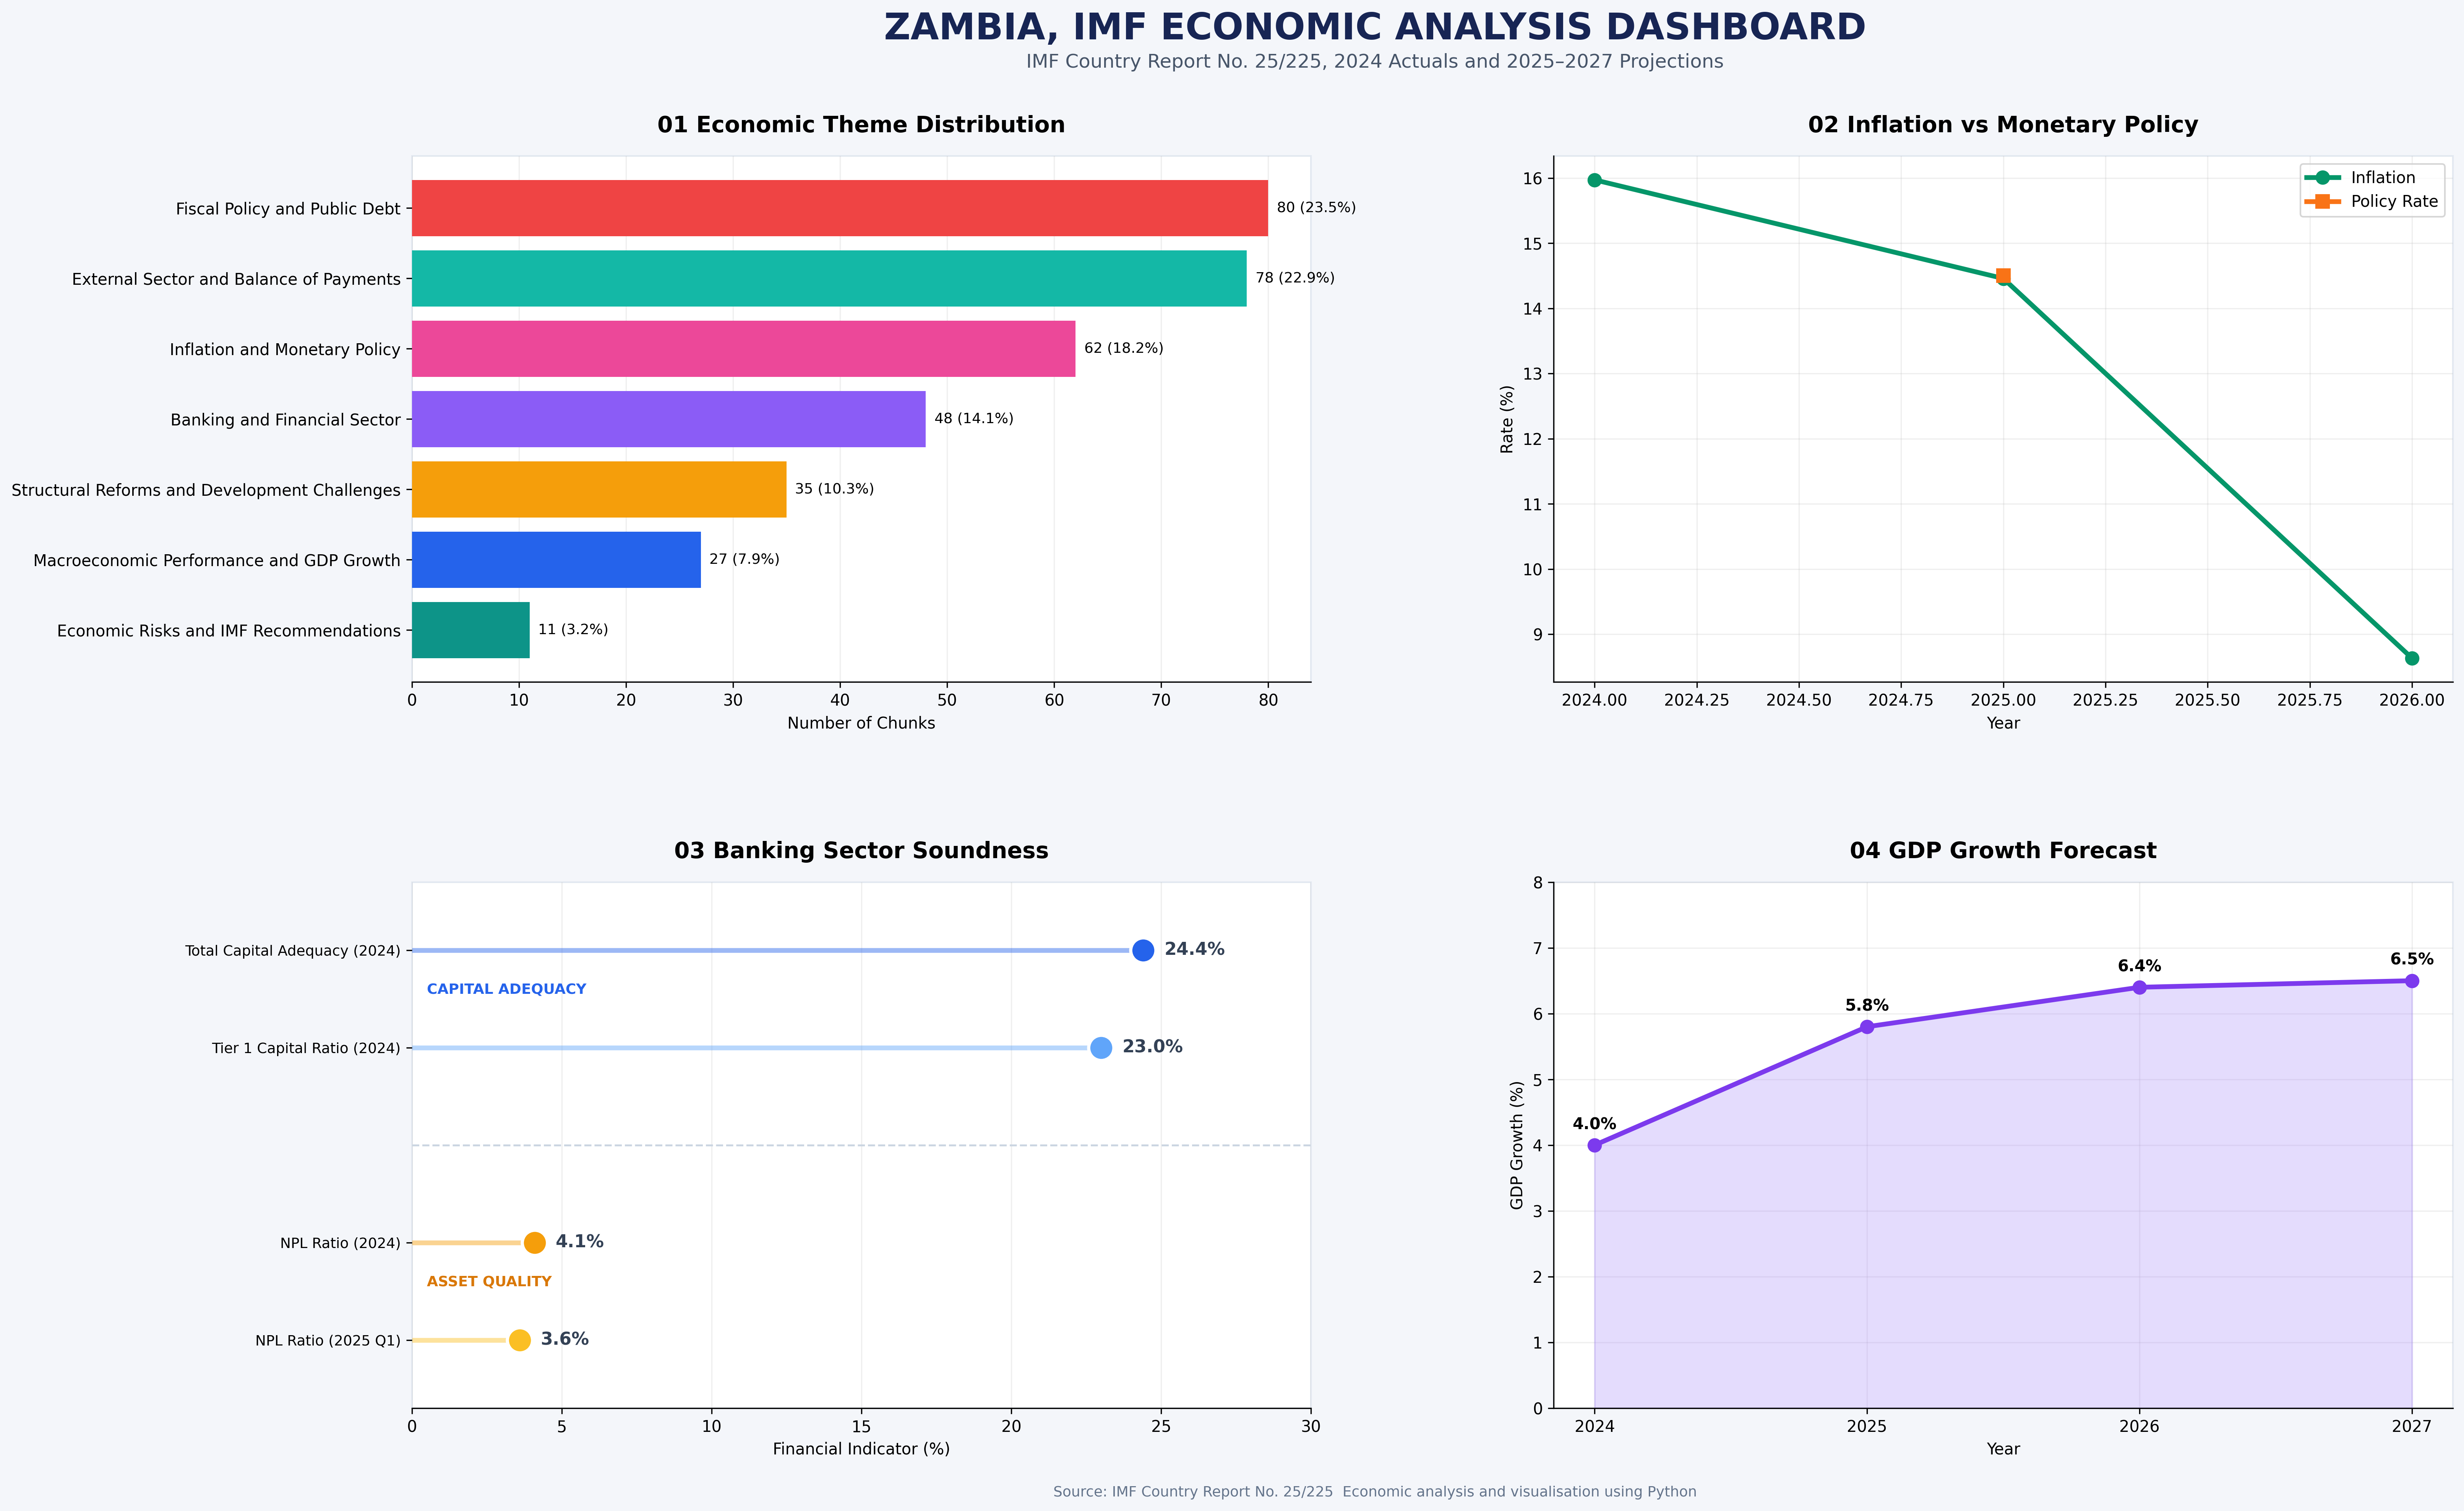

In [ ]:
from IPython.display import Image, display

display(Image(filename="Zambia_Professional_Economic_Dashboard.png"))

In [ ]:
display(
    financial_df[
        financial_df["indicator"].isin([
            "Headline inflation rate",
            "Central bank policy rate"
        ])
    ][[
        "indicator",
        "value_pct",
        "period",
        "status",
        "supporting_evidence"
    ]].sort_values(["indicator", "period"])
)

,indicator,value_pct,period,status,supporting_evidence
19,Central bank policy rate,14.5,February 2025,actual,The Monetary Policy Committee raised its policy rate by another 50 basis points (bps) to 14.5 percent in February
43,Central bank policy rate,14.5,February 2025,actual,"further by 50 basis points in February 2025, bringing the rate to 14.5 percent"
9,Central bank policy rate,14.5,May 2025,actual,"followed with an additional 50 bps increase in February 2025, bringing the rate to 14.5 percent, and held it steady in May."
20,Central bank policy rate,14.5,May 2025,actual,"In May, the Bank of Zambia (BoZ) maintained the policy rate at 14.5 percent"
44,Central bank policy rate,14.5,May 2025,actual,The rate was maintained in May
3,Headline inflation rate,15.0,2024,actual,"Driven by higher food prices and kwacha depreciation, inflation averaged 15 percent in 2024."
14,Headline inflation rate,15.0,2024,actual,"Inflation averaged 15.0 percent, ending the year at 16.7 percent y/y."
29,Headline inflation rate,15.0,2024,actual,Inflation (Annual Average) Current DSA for 2024 is 15.0 percent.
30,Headline inflation rate,16.7,2024 (End of Period),actual,Inflation (End of Period) Current DSA for 2024 is 16.7 percent.
8,Headline inflation rate,14.2,2025,forecast,"CPI inflation, average (percent) 2025 Proj. 14.2"


**Final Dashboard**

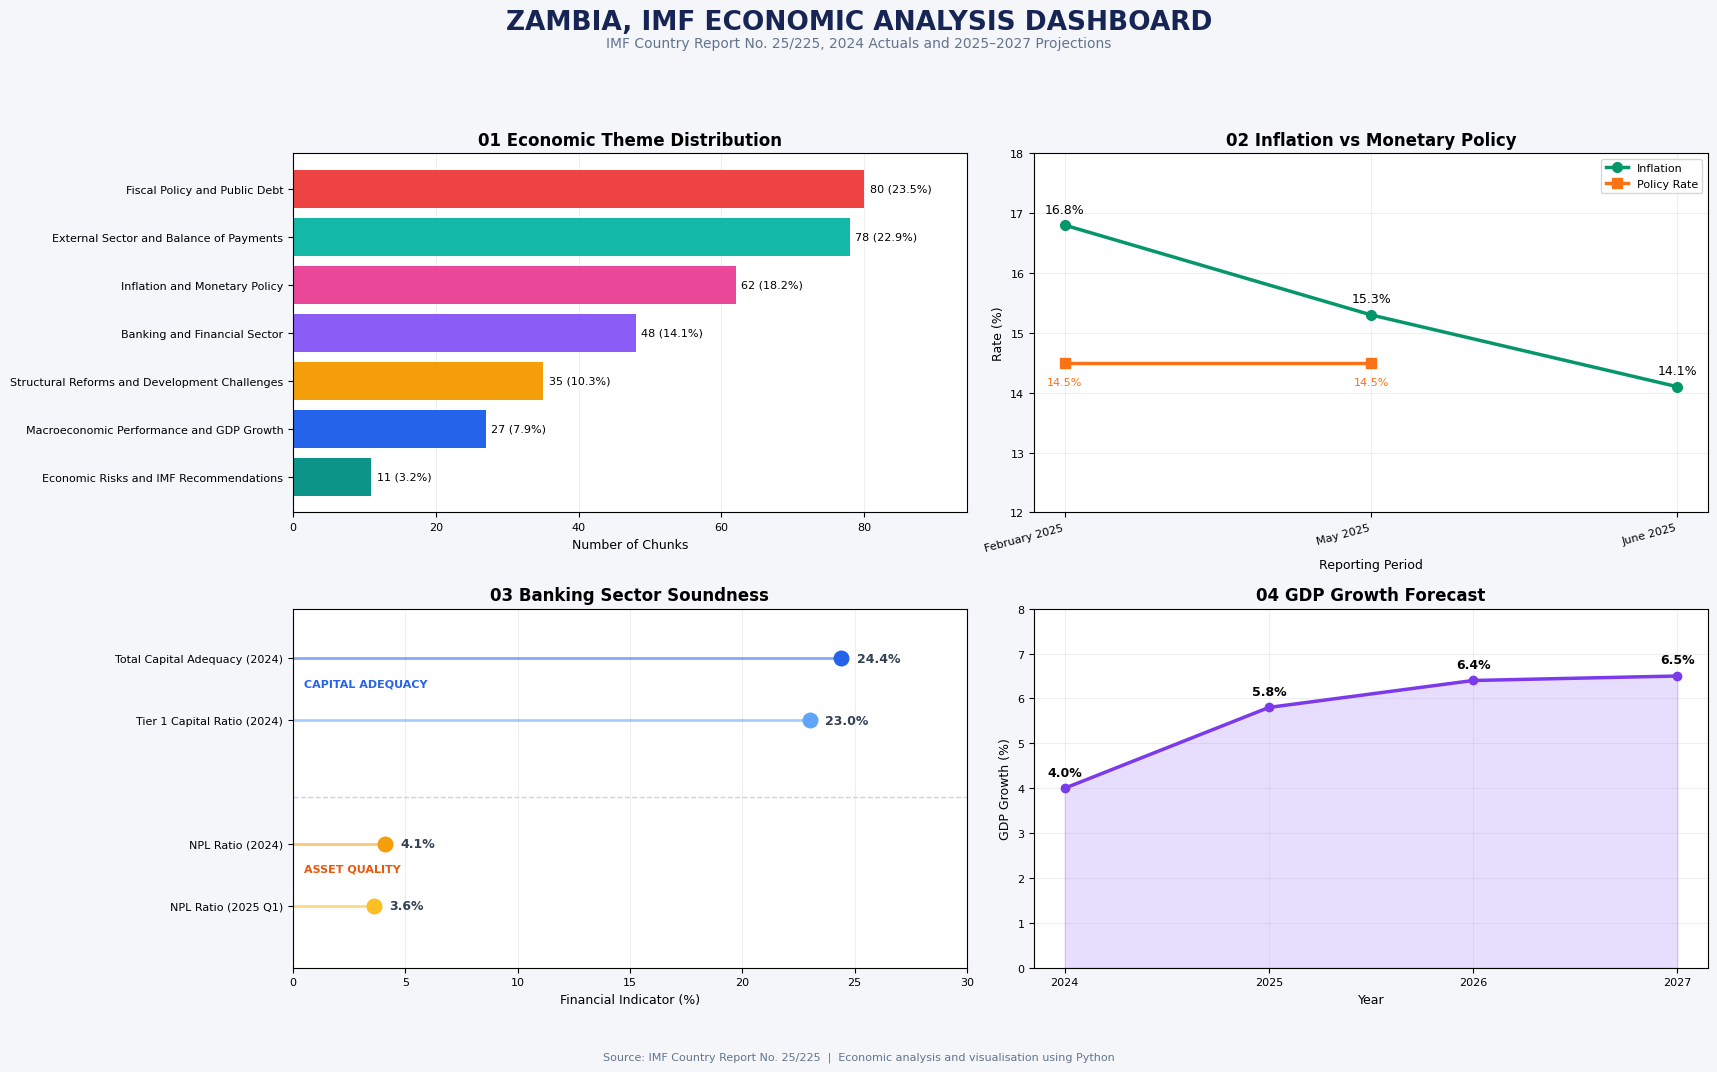

Dashboard generated successfully.
PNG: Zambia_Professional_Economic_Dashboard.png
PDF: Zambia_Professional_Economic_Dashboard.pdf


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["font.family"] = "DejaVu Sans"

fig, axes = plt.subplots(2, 2, figsize=(18, 11))

fig.patch.set_facecolor("#F4F6FA")

for ax in axes.flat:
    ax.set_facecolor("white")

fig.suptitle(
    "ZAMBIA, IMF ECONOMIC ANALYSIS DASHBOARD",
    fontsize=19,
    fontweight="bold",
    color="#172554",
    y=0.98
)

fig.text(
    0.5,
    0.945,
    "IMF Country Report No. 25/225, 2024 Actuals and 2025–2027 Projections",
    ha="center",
    fontsize=10,
    color="#64748B"
)

theme_order = theme_summary.sort_values(
    "chunk_count",
    ascending=True
)

theme_colors = [
    "#0D9488",
    "#2563EB",
    "#F59E0B",
    "#8B5CF6",
    "#EC4899",
    "#14B8A6",
    "#EF4444"
]

ax1 = axes[0, 0]

bars = ax1.barh(
    theme_order["theme"],
    theme_order["chunk_count"],
    color=theme_colors,
    height=0.8
)

for bar, percentage in zip(
    bars,
    theme_order["percentage"]
):
    width = bar.get_width()
    ax1.text(
        width + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)} ({percentage:.1f}%)",
        va="center",
        fontsize=8
    )

ax1.set_title(
    "01 Economic Theme Distribution",
    fontweight="bold",
    fontsize=12
)

ax1.set_xlabel("Number of Chunks", fontsize=9)
ax1.set_xlim(0, max(theme_order["chunk_count"]) * 1.18)
ax1.grid(axis="x", alpha=0.2)
ax1.set_axisbelow(True)
ax1.tick_params(axis="y", labelsize=8)
ax1.tick_params(axis="x", labelsize=8)


ax2 = axes[0, 1]

periods = [
    "February 2025",
    "May 2025",
    "June 2025"
]

x = np.arange(len(periods))

inflation = [16.8, 15.3, 14.1]
policy_rate = [14.5, 14.5]

ax2.plot(
    x,
    inflation,
    color="#059669",
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Inflation"
)

ax2.plot(
    x[:2],
    policy_rate,
    color="#F97316",
    marker="s",
    linewidth=2.5,
    markersize=7,
    label="Policy Rate"
)

for i, value in enumerate(inflation):
    ax2.annotate(
        f"{value:.1f}%",
        (x[i], value),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

for i, value in enumerate(policy_rate):
    ax2.annotate(
        f"{value:.1f}%",
        (x[i], value),
        xytext=(0, -16),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="#F97316"
    )

ax2.set_title(
    "02 Inflation vs Monetary Policy",
    fontweight="bold",
    fontsize=12
)

ax2.set_xlabel("Reporting Period", fontsize=9)
ax2.set_ylabel("Rate (%)", fontsize=9)
ax2.set_xticks(x)
ax2.set_xticklabels(periods, rotation=15, ha="right")
ax2.set_ylim(12, 18)
ax2.grid(alpha=0.2)
ax2.set_axisbelow(True)
ax2.legend(fontsize=8, loc="upper right")
ax2.tick_params(axis="both", labelsize=8)


ax3 = axes[1, 0]

bank_labels = [
    "Total Capital Adequacy (2024)",
    "Tier 1 Capital Ratio (2024)",
    "NPL Ratio (2024)",
    "NPL Ratio (2025 Q1)"
]

bank_values = [24.4, 23.0, 4.1, 3.6]

bank_positions = [3, 2, 0, -1]

bank_colors = [
    "#2563EB",
    "#60A5FA",
    "#F59E0B",
    "#FBBF24"
]

for position, value, color in zip(
    bank_positions,
    bank_values,
    bank_colors
):
    ax3.hlines(
        position,
        0,
        value,
        color=color,
        linewidth=2,
        alpha=0.55
    )

    ax3.scatter(
        value,
        position,
        color=color,
        s=110,
        zorder=3
    )

    ax3.text(
        value + 0.7,
        position,
        f"{value:.1f}%",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#334155"
    )

ax3.set_yticks(bank_positions)
ax3.set_yticklabels(bank_labels, fontsize=8)
ax3.set_xlim(0, 30)
ax3.set_ylim(-2, 3.8)

ax3.axhline(
    0.75,
    color="#CBD5E1",
    linestyle="--",
    linewidth=1
)

ax3.text(
    0.5,
    2.55,
    "CAPITAL ADEQUACY",
    color="#2563EB",
    fontsize=8,
    fontweight="bold"
)

ax3.text(
    0.5,
    -0.45,
    "ASSET QUALITY",
    color="#EA580C",
    fontsize=8,
    fontweight="bold"
)

ax3.set_title(
    "03 Banking Sector Soundness",
    fontweight="bold",
    fontsize=12
)

ax3.set_xlabel("Financial Indicator (%)", fontsize=9)
ax3.grid(axis="x", alpha=0.2)
ax3.set_axisbelow(True)
ax3.tick_params(axis="x", labelsize=8)


ax4 = axes[1, 1]

gdp_years = [2024, 2025, 2026, 2027]
gdp_growth = [4.0, 5.8, 6.4, 6.5]

ax4.plot(
    gdp_years,
    gdp_growth,
    color="#7C3AED",
    marker="o",
    linewidth=2.5,
    markersize=6
)

ax4.fill_between(
    gdp_years,
    gdp_growth,
    color="#8B5CF6",
    alpha=0.2
)

for year, value in zip(gdp_years, gdp_growth):
    ax4.annotate(
        f"{value:.1f}%",
        (year, value),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

ax4.set_title(
    "04 GDP Growth Forecast",
    fontweight="bold",
    fontsize=12
)

ax4.set_xlabel("Year", fontsize=9)
ax4.set_ylabel("GDP Growth (%)", fontsize=9)
ax4.set_xticks(gdp_years)
ax4.set_ylim(0, 8)
ax4.grid(alpha=0.2)
ax4.set_axisbelow(True)
ax4.tick_params(axis="both", labelsize=8)


fig.text(
    0.5,
    0.025,
    "Source: IMF Country Report No. 25/225  |  Economic analysis and visualisation using Python",
    ha="center",
    fontsize=8,
    color="#64748B"
)

plt.tight_layout(rect=[0.02, 0.06, 0.98, 0.92])

plt.savefig(
    "Zambia_Professional_Economic_Dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.savefig(
    "Zambia_Professional_Economic_Dashboard.pdf",
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Dashboard generated successfully.")
print("PNG: Zambia_Professional_Economic_Dashboard.png")
print("PDF: Zambia_Professional_Economic_Dashboard.pdf")
